In [1]:
%pip install numpy pandas scipy scikit-learn matplotlib threadpoolctl


Note: you may need to restart the kernel to use updated packages.


In [2]:
from dataclasses import dataclass
from time import perf_counter

import numpy as np
from sklearn.metrics import balanced_accuracy_score
from sklearn.neighbors import NearestNeighbors


def decode_particle(u):
    u = np.asarray(u, dtype=float)
    return 10.0 ** (-3 * (1 - u[:-1])), 2 * min(int(26 * u[-1]), 25) + 1


def _prepare_training_data(X, y):
    X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=int)
    return X, y, np.bincount(y)


def _vote(labels, distances, counts, vote):
    votes = np.ones_like(distances)
    if vote == "balanced_distance":
        factors = counts.sum() / (len(counts) * counts)
        votes = factors[labels] / (distances + 1e-12)
    scores = np.zeros((len(labels), len(counts)))
    rows = np.broadcast_to(np.arange(len(labels))[:, None], labels.shape)
    np.add.at(scores, (rows, labels), votes)
    return scores.argmax(axis=1)


def _loo_neighbors_numpy(X, k):
    norms = np.einsum("ij,ij->i", X, X)
    distances2 = X @ X.T
    distances2 *= -2
    distances2 += norms[:, None]
    distances2 += norms[None, :]
    np.maximum(distances2, 0, out=distances2)
    np.fill_diagonal(distances2, np.inf)
    indices = np.argpartition(distances2, k - 1, axis=1)[:, :k]
    return np.sqrt(np.take_along_axis(distances2, indices, axis=1)), indices


def _loo_neighbors_sklearn(X, k):
    model = NearestNeighbors(n_neighbors=k + 1, algorithm="brute", metric="euclidean", n_jobs=1)
    distances, indices = model.fit(X).kneighbors(X)
    distances[indices == np.arange(len(X))[:, None]] = np.inf
    order = np.argpartition(distances, k - 1, axis=1)[:, :k]
    return np.take_along_axis(distances, order, axis=1), np.take_along_axis(indices, order, axis=1)


def loo_predict(X, y, weights, k, *, backend="numpy", vote="balanced_distance"):
    X, y, counts = _prepare_training_data(X, y)
    neighbors = _loo_neighbors_numpy if backend == "numpy" else _loo_neighbors_sklearn
    distances, indices = neighbors(np.ascontiguousarray(X * weights), k)
    return _vote(y[indices], distances, counts, vote)


def weighted_knn_predict(X_train, y_train, X_query, weights, k, *,
                         vote="balanced_distance", batch_size=512):
    X_train, y_train, counts = _prepare_training_data(X_train, y_train)
    model = NearestNeighbors(n_neighbors=k, algorithm="brute", metric="euclidean", n_jobs=1)
    model.fit(np.ascontiguousarray(X_train * weights))
    predictions = np.empty(len(X_query), dtype=int)
    for start in range(0, len(X_query), batch_size):
        stop = start + batch_size
        distances, indices = model.kneighbors(np.ascontiguousarray(X_query[start:stop] * weights))
        predictions[start:stop] = _vote(y_train[indices], distances, counts, vote)
    return predictions


class LOOFitness:
    def __init__(self, X, y, backend="numpy"):
        self.X, self.y, self.counts = _prepare_training_data(X, y)
        self.backend = backend
        self.n_evaluations = 0

    def evaluate(self, weights, k):
        prediction = loo_predict(self.X, self.y, weights, k, backend=self.backend)
        self.n_evaluations += 1
        return float(1 - balanced_accuracy_score(self.y, prediction))

    def __call__(self, u):
        return self.evaluate(*decode_particle(u))


@dataclass(frozen=True)
class PSOConfig:
    n_particles: int = 20
    n_iterations: int = 25
    omega: float | tuple = 0.7
    c1: float = 1.5
    c2: float = 1.5
    vmax: float = 0.2

    @property
    def budget(self):
        return self.n_particles * self.n_iterations

    def inertia_at(self, iteration):
        values = np.asarray(self.omega).ravel()
        fraction = (iteration - 2) / max(1, self.n_iterations - 2)
        return float(values[0] + fraction * (values[-1] - values[0]))


def pso(fitness, dim, config, seed):
    started = perf_counter()
    streams = np.random.SeedSequence(seed).spawn(3)
    positions = np.random.default_rng(streams[0]).uniform(0, 1, (config.n_particles, dim))
    velocities = np.random.default_rng(streams[1]).uniform(-config.vmax, config.vmax, positions.shape)
    rng = np.random.default_rng(streams[2])
    pbest_positions, pbest_values = positions.copy(), np.full(config.n_particles, np.inf)
    gbest_value, history = np.inf, []
    for iteration in range(1, config.n_iterations + 1):
        omega, boundary_fraction = None, 0.0
        if iteration > 1:
            omega = config.inertia_at(iteration)
            r1, r2 = rng.uniform(size=positions.shape), rng.uniform(size=positions.shape)
            velocities = (omega * velocities + config.c1 * r1 * (pbest_positions - positions)
                          + config.c2 * r2 * (gbest_position - positions))
            np.clip(velocities, -config.vmax, config.vmax, out=velocities)
            proposed = positions + velocities
            crossed = (proposed < 0) | (proposed > 1)
            positions = np.clip(proposed, 0, 1)
            velocities[crossed] = 0
            boundary_fraction = float(crossed.mean())
        values = np.asarray([float(fitness(u)) for u in positions])
        improved = values < pbest_values
        pbest_positions[improved], pbest_values[improved] = positions[improved], values[improved]
        best = int(pbest_values.argmin())
        if pbest_values[best] < gbest_value:
            gbest_position, gbest_value = pbest_positions[best].copy(), float(pbest_values[best])
        history.append({
            "iteration": iteration, "evaluations": iteration * config.n_particles,
            "gbest_fitness": gbest_value, "mean_pbest_fitness": float(pbest_values.mean()),
            "diversity": float(np.linalg.norm(positions - positions.mean(axis=0), axis=1).mean()),
            "mean_speed": float(np.linalg.norm(velocities, axis=1).mean()),
            "improved_fraction": float(improved.mean()), "omega": omega,
            "boundary_fraction": boundary_fraction,
        })
    return {"u": gbest_position, "fitness": gbest_value, "history": history,
            "n_evaluations": config.budget, "seconds": perf_counter() - started}


def random_search(fitness, dim, budget, seed, log_every=20):
    started = perf_counter()
    rng = np.random.default_rng(np.random.SeedSequence(seed, spawn_key=(3,)))
    best_value, history = np.inf, []
    for evaluation in range(1, budget + 1):
        u = rng.uniform(size=dim)
        value = float(fitness(u))
        if value < best_value:
            best_position, best_value = u.copy(), value
        if evaluation % log_every == 0 or evaluation == budget:
            history.append({"evaluations": evaluation, "gbest_fitness": best_value})
    return {"u": best_position, "fitness": best_value, "history": history,
            "n_evaluations": budget, "seconds": perf_counter() - started}


In [3]:
from dataclasses import asdict, replace
from itertools import product
from pathlib import Path

import pandas as pd
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits


def read_dataset(base, split):
    data = pd.read_csv(BASES_DIR / base / f"{base}-{split}.csv", header=None)
    return data.iloc[:, :-1].to_numpy(), data.iloc[:, -1].to_numpy(dtype=int)


def experiment_seed(base, seed, stream, size=0):
    return int(np.random.SeedSequence([20261124, BASES.index(base), seed, stream, size])
               .generate_state(1)[0])


def run_directory(experiment, seed):
    return (OUTPUT_DIR / experiment["base"] / f'n-{experiment["sample_size"]:05d}'
            / experiment["method"] / experiment["config_id"] / f"seed-{seed:04d}")


def save_statistics(experiment, metrics):
    rows = [pd.read_csv(run_directory(experiment, seed) / "summary.csv") for seed in SEEDS]
    statistics = pd.concat(rows)[metrics].agg(["mean", "std"]).T
    statistics.to_csv(run_directory(experiment, SEEDS[0]).parent / "statistics.csv", index_label="metric")


def run_experiment(experiment, seed):
    base, size, method = experiment["base"], experiment["sample_size"], experiment["method"]
    X_train, y_train, _ = TRAIN[base]
    splitter = StratifiedShuffleSplit(n_splits=1, train_size=size,
        random_state=experiment_seed(base, seed, 0, size))
    indices, _ = next(splitter.split(X_train, y_train))
    indices = np.sort(indices)
    X, y = X_train[indices], y_train[indices]
    fitness = LOOFitness(X, y)
    with threadpool_limits(limits=1):
        started = perf_counter()
        if method == "pso":
            result = pso(fitness, X.shape[1] + 1, PSO_CONFIGS[experiment["config_id"]],
                         experiment_seed(base, seed, 1))
            weights, k = decode_particle(result["u"])
        elif method == "random":
            result = random_search(fitness, X.shape[1] + 1, BUDGET, experiment_seed(base, seed, 1))
            weights, k = decode_particle(result["u"])
        else:
            weights, k = np.ones(X.shape[1]), 5
            history, best = [], np.inf
            candidates = range(1, 52, 2) if method == "unweighted" else [5]
            for evaluation, candidate in enumerate(candidates, 1):
                value = (fitness.evaluate(weights, candidate) if method == "unweighted" else
                         1 - balanced_accuracy_score(y, loo_predict(X, y, weights, candidate, vote="uniform")))
                if value < best:
                    best, k = value, candidate
                history.append({"evaluations": evaluation, "gbest_fitness": float(best)})
            result = {"u": np.r_[weights, (k // 2 + 0.5) / 26], "fitness": best,
                      "history": history, "n_evaluations": len(candidates),
                      "seconds": perf_counter() - started}
    history = pd.DataFrame(result["history"])
    auc = np.trapezoid(np.r_[history.gbest_fitness.iloc[0], history.gbest_fitness],
                       np.r_[0, history.evaluations]) / result["n_evaluations"]
    summary = {**experiment, "seed": seed, "fitness": float(result["fitness"]),
               "loo_bacc": float(1 - result["fitness"]), "k": int(k),
               "search_seconds": result["seconds"], "n_evaluations": result["n_evaluations"],
               "low_weight_fraction": float(np.mean(weights < 0.01)), "gbest_auc": float(auc)}
    directory = run_directory(experiment, seed)
    directory.mkdir(parents=True, exist_ok=True)
    pd.DataFrame([summary]).to_csv(directory / "summary.csv", index=False)
    history.to_csv(directory / "history.csv", index=False)
    pd.DataFrame({"attribute": np.arange(len(weights)), "weight": weights}).to_csv(
        directory / "weights.csv", index=False)
    pd.DataFrame({"coordinate": np.arange(len(result["u"])), "u": result["u"]}).to_csv(
        directory / "particle.csv", index=False)
    print(f'{base} | {method}/{experiment["config_id"]} | n={size} | seed={seed} | {result["seconds"]:.2f}s')
    return summary


def execute_grid(grid):
    rows = []
    for experiment in grid:
        for seed in SEEDS:
            rows.append(run_experiment(experiment, seed))
        save_statistics(experiment, TRAIN_METRICS)
    return pd.DataFrame(rows)


def save_grid(grid):
    rows = []
    for experiment in grid:
        parameters = asdict(PSO_CONFIGS[experiment["config_id"]]) if experiment["method"] == "pso" else {}
        rows.append({**experiment, **parameters})
    pd.DataFrame(rows).to_csv(OUTPUT_DIR / "grid.csv", index=False)


def evaluate_test(grid):
    for base in BASES:
        X_train, y_train, scaler = TRAIN[base]
        X_test, y_test = read_dataset(base, "test")
        X_test = scaler.transform(X_test)
        with threadpool_limits(limits=1):
            started = perf_counter()
            prediction = KNeighborsClassifier().fit(X_train, y_train).predict(X_test)
            standard_seconds = perf_counter() - started
            standard_bacc = balanced_accuracy_score(y_test, prediction)
            np.testing.assert_array_equal(prediction, weighted_knn_predict(
                X_train, y_train, X_test, np.ones(X_train.shape[1]), 5, vote="uniform"))
        for experiment in (row for row in grid if row["base"] == base):
            for seed in SEEDS:
                directory = run_directory(experiment, seed)
                summary = pd.read_csv(directory / "summary.csv")
                if experiment["method"] == "standard":
                    score, seconds = standard_bacc, standard_seconds
                else:
                    weights = pd.read_csv(directory / "weights.csv")["weight"].to_numpy()
                    k = int(summary["k"].iloc[0])
                    with threadpool_limits(limits=1):
                        started = perf_counter()
                        prediction = weighted_knn_predict(X_train, y_train, X_test, weights, k)
                        seconds = perf_counter() - started
                    score = balanced_accuracy_score(y_test, prediction)
                summary["test_bacc"], summary["test_seconds"] = score, seconds
                summary["gap"] = summary["loo_bacc"] - score
                summary.to_csv(directory / "summary.csv", index=False)
            save_statistics(experiment, TRAIN_METRICS + ["test_bacc", "test_seconds", "gap"])
        print(f"Teste concluído: {base}")


In [4]:
BASES_DIR = Path.cwd() / "bases"
OUTPUT_DIR = Path.cwd() / "resultados_tp2" / "experimentos"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BASES = ("aurora", "boreal", "caatinga")
SEEDS = (0, 1, 2, 3, 4)
BUDGET = 500
REFERENCE = PSOConfig()
PSO_CONFIGS = {
    "ref": REFERENCE,
    "w040": replace(REFERENCE, omega=0.4),
    "w090": replace(REFERENCE, omega=0.9),
    "w_linear": replace(REFERENCE, omega=(0.9, 0.4)),
    "cognitive": replace(REFERENCE, c1=2.5, c2=0.5),
    "social": replace(REFERENCE, c1=0.5, c2=2.5),
    "v005": replace(REFERENCE, vmax=0.05),
    "v100": replace(REFERENCE, vmax=1.0),
    "swarm10": replace(REFERENCE, n_particles=10, n_iterations=50),
    "swarm50": replace(REFERENCE, n_particles=50, n_iterations=10),
}
TRAIN_METRICS = ["fitness", "loo_bacc", "k", "search_seconds", "low_weight_fraction", "gbest_auc"]


In [5]:
TRAIN = {}
for base in BASES:
    X, y = read_dataset(base, "train")
    scaler = StandardScaler().fit(X)
    TRAIN[base] = scaler.transform(X), y, scaler


In [6]:
methods = [("pso", "ref"), ("random", "uniform500"), ("unweighted", "kgrid26"),
           ("standard", "sklearn5")] + [("pso", name) for name in PSO_CONFIGS if name != "ref"]
INITIAL_GRID = [{"base": base, "sample_size": 1000, "method": method, "config_id": config}
                for (method, config), base in product(methods, BASES)]
RESULTS = execute_grid(INITIAL_GRID)


aurora | pso/ref | n=1000 | seed=0 | 10.05s
aurora | pso/ref | n=1000 | seed=1 | 10.44s
aurora | pso/ref | n=1000 | seed=2 | 11.38s
aurora | pso/ref | n=1000 | seed=3 | 9.85s
aurora | pso/ref | n=1000 | seed=4 | 10.18s
boreal | pso/ref | n=1000 | seed=0 | 9.29s
boreal | pso/ref | n=1000 | seed=1 | 9.13s
boreal | pso/ref | n=1000 | seed=2 | 9.25s
boreal | pso/ref | n=1000 | seed=3 | 9.18s
boreal | pso/ref | n=1000 | seed=4 | 9.00s
caatinga | pso/ref | n=1000 | seed=0 | 9.86s
caatinga | pso/ref | n=1000 | seed=1 | 9.96s
caatinga | pso/ref | n=1000 | seed=2 | 9.63s
caatinga | pso/ref | n=1000 | seed=3 | 9.89s
caatinga | pso/ref | n=1000 | seed=4 | 10.15s
aurora | random/uniform500 | n=1000 | seed=0 | 9.24s
aurora | random/uniform500 | n=1000 | seed=1 | 9.25s
aurora | random/uniform500 | n=1000 | seed=2 | 9.15s
aurora | random/uniform500 | n=1000 | seed=3 | 9.29s
aurora | random/uniform500 | n=1000 | seed=4 | 8.96s
boreal | random/uniform500 | n=1000 | seed=0 | 8.60s
boreal | random/unifor

In [7]:
pso_results = RESULTS[RESULTS["method"] == "pso"]
by_base = pso_results.groupby(["base", "config_id"], as_index=False).agg(
    mean_fitness=("fitness", "mean"), mean_auc=("gbest_auc", "mean"), std_fitness=("fitness", "std"))
by_base["rank"] = by_base.groupby("base")["mean_fitness"].rank()
ranking = by_base.groupby("config_id", as_index=False).agg(
    mean_rank=("rank", "mean"), mean_fitness=("mean_fitness", "mean"),
    mean_auc=("mean_auc", "mean"), mean_std=("std_fitness", "mean"))
ranking = ranking.sort_values(["mean_rank", "mean_fitness", "mean_auc", "mean_std", "config_id"])
ranking.to_csv(OUTPUT_DIR / "selection.csv", index=False)
SELECTED = ranking.iloc[0]["config_id"]
print(f"Configuração final: {SELECTED}")


Configuração final: w_linear


In [8]:
SAMPLE_GRID = [{"base": base, "sample_size": size, "method": "pso", "config_id": SELECTED}
               for base, size in product(BASES, (250, 2000))]
SAMPLE_RESULTS = execute_grid(SAMPLE_GRID)
GRID = INITIAL_GRID + SAMPLE_GRID
save_grid(GRID)


aurora | pso/w_linear | n=250 | seed=0 | 1.69s
aurora | pso/w_linear | n=250 | seed=1 | 1.65s
aurora | pso/w_linear | n=250 | seed=2 | 1.64s
aurora | pso/w_linear | n=250 | seed=3 | 1.71s
aurora | pso/w_linear | n=250 | seed=4 | 1.64s
aurora | pso/w_linear | n=2000 | seed=0 | 28.32s
aurora | pso/w_linear | n=2000 | seed=1 | 27.94s
aurora | pso/w_linear | n=2000 | seed=2 | 28.01s
aurora | pso/w_linear | n=2000 | seed=3 | 27.89s
aurora | pso/w_linear | n=2000 | seed=4 | 30.56s
boreal | pso/w_linear | n=250 | seed=0 | 1.86s
boreal | pso/w_linear | n=250 | seed=1 | 1.66s
boreal | pso/w_linear | n=250 | seed=2 | 1.73s
boreal | pso/w_linear | n=250 | seed=3 | 1.76s
boreal | pso/w_linear | n=250 | seed=4 | 1.63s
boreal | pso/w_linear | n=2000 | seed=0 | 28.76s
boreal | pso/w_linear | n=2000 | seed=1 | 30.26s
boreal | pso/w_linear | n=2000 | seed=2 | 28.54s
boreal | pso/w_linear | n=2000 | seed=3 | 27.33s
boreal | pso/w_linear | n=2000 | seed=4 | 27.20s
caatinga | pso/w_linear | n=250 | seed=0

In [9]:
evaluate_test(GRID)


Teste concluído: aurora
Teste concluído: boreal
Teste concluído: caatinga


In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def save_figure(fig, directory, name):
    fig.savefig(directory / f"{name}.png", dpi=150, bbox_inches="tight")
    fig.savefig(directory / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


def mean_curve(ax, frame, metric, label, **style):
    statistics = frame.groupby("evaluations")[metric].agg(["mean", "std"])
    x, mean, deviation = statistics.index, statistics["mean"], statistics["std"]
    line, = ax.plot(x, mean, label=label, **style)
    ax.fill_between(x, mean - deviation, mean + deviation, color=line.get_color(), alpha=0.12)


def write_statistics(frame, metrics, keys, path):
    statistics = frame.groupby(keys)[metrics].agg(["mean", "std"])
    statistics.columns = ["_".join(column) for column in statistics.columns]
    statistics.reset_index().to_csv(path, index=False)


def paired_difference(source, target, base, config_id, other_method):
    paired = source.merge(target, on="seed", suffixes=("_pso", "_other"))
    result = {"base": base, "pso_config": config_id, "other_method": other_method, "n_pairs": len(paired)}
    for metric in ("test_bacc", "loo_bacc", "fitness"):
        difference = paired[f"{metric}_pso"] - paired[f"{metric}_other"]
        result.update({f"{metric}_difference_mean": difference.mean(),
                       f"{metric}_difference_std": difference.std(ddof=1)})
        if metric != "fitness":
            result.update({f"{metric}_wins": int((difference > 1e-12).sum()),
                           f"{metric}_ties": int((difference.abs() <= 1e-12).sum()),
                           f"{metric}_losses": int((difference < -1e-12).sum())})
    return result


def generate_figures(output_dir, seeds=(0, 1, 2, 3, 4)):
    output_dir = Path(output_dir)
    tables, figures = output_dir / "tabelas", output_dir / "figuras"
    tables.mkdir(exist_ok=True)
    figures.mkdir(exist_ok=True)
    grid = pd.read_csv(output_dir / "grid.csv")
    selected = pd.read_csv(output_dir / "selection.csv").iloc[0]["config_id"]
    runs, histories, weights = [], [], []
    for experiment in grid.itertuples(index=False):
        for seed in seeds:
            directory = (output_dir / experiment.base / f"n-{experiment.sample_size:05d}"
                         / experiment.method / experiment.config_id / f"seed-{seed:04d}")
            runs.append(pd.read_csv(directory / "summary.csv"))
            history = pd.read_csv(directory / "history.csv")
            histories.append(history.assign(base=experiment.base, method=experiment.method,
                config_id=experiment.config_id, sample_size=experiment.sample_size, seed=seed))
            if experiment.sample_size == 1000 and (experiment.method == "random" or
                    (experiment.method == "pso" and experiment.config_id == selected)):
                w = pd.read_csv(directory / "weights.csv")["weight"].to_numpy()
                weights.append(pd.DataFrame({"base": experiment.base, "method": experiment.method,
                    "seed": seed, "attribute": np.arange(len(w)), "weight": w,
                    "log10_weight": np.log10(w), "low_weight": w < 0.01}))
    runs, histories, weights = pd.concat(runs), pd.concat(histories), pd.concat(weights)
    runs.to_csv(tables / "execucoes.csv", index=False)
    histories.to_csv(tables / "historicos.csv", index=False)
    keys = ["base", "method", "config_id", "sample_size"]
    write_statistics(runs, ["fitness", "loo_bacc", "test_bacc", "gap", "search_seconds", "test_seconds",
                           "k", "n_evaluations", "low_weight_fraction", "gbest_auc"],
                     keys, tables / "estatisticas.csv")
    weights.to_csv(tables / "pesos.csv", index=False)
    weights.groupby(["base", "method", "attribute"]).agg(
        mean_weight=("weight", "mean"), std_weight=("weight", "std"),
        mean_log10_weight=("log10_weight", "mean"), low_weight_frequency=("low_weight", "mean")
    ).reset_index().to_csv(tables / "pesos-por-atributo.csv", index=False)
    fractions = weights.groupby(["base", "method", "seed"])["low_weight"].mean().reset_index()
    fractions["uniform_reference"] = 1 / 3
    fractions.to_csv(tables / "fracao-pesos-baixos.csv", index=False)
    convergence = []
    for key, history in histories.groupby(keys + ["seed"]):
        history = history.sort_values("evaluations")
        improved = history["gbest_fitness"].diff().lt(0)
        last = history.loc[improved, "evaluations"].max() if improved.any() else history["evaluations"].iloc[0]
        tail = history.loc[history["evaluations"] <= history["evaluations"].iloc[-1] - 100, "gbest_fitness"]
        gain = (tail.iloc[-1] if len(tail) else history["gbest_fitness"].iloc[0]) - history["gbest_fitness"].iloc[-1]
        convergence.append(dict(zip(keys + ["seed"], key), last_improvement_evaluation=last,
                                fitness_gain_last_100=gain))
    pd.DataFrame(convergence).to_csv(tables / "convergencia.csv", index=False)
    labels = {"ref": "Referência", "w040": "ω = 0,4", "w090": "ω = 0,9",
        "w_linear": "ω: 0,9 → 0,4", "cognitive": "Cognitiva", "social": "Social",
        "v005": "vmax = 0,05", "v100": "vmax = 1", "swarm10": "10 × 50", "swarm50": "50 × 10"}
    groups = {"todas": list(labels), "inercia": ["ref", "w040", "w090", "w_linear"],
        "atracao": ["ref", "cognitive", "social"], "vmax": ["ref", "v005", "v100"],
        "enxame": ["ref", "swarm10", "swarm50"]}
    metrics = {"gbest_fitness": "Fitness do gbest", "mean_pbest_fitness": "Fitness média dos pbest",
        "diversity": "Diversidade das posições", "mean_speed": "Norma média da velocidade",
        "improved_fraction": "Fração de melhorias de pbest"}
    comparisons, rankings = [], []
    for base in grid["base"].unique():
        base_runs = runs[(runs["base"] == base) & (runs["sample_size"] == 1000)]
        base_history = histories[(histories["base"] == base) & (histories["sample_size"] == 1000)]
        for group, configs in groups.items():
            fig, axes = plt.subplots(3, 2, figsize=(13, 11), constrained_layout=True)
            axes = axes.ravel()
            for config in configs:
                source = base_history[(base_history["method"] == "pso") & (base_history["config_id"] == config)]
                for ax, metric in zip(axes, metrics):
                    mean_curve(ax, source, metric, labels[config])
            mean_curve(axes[0], base_history[base_history["method"] == "random"], "gbest_fitness",
                       "Busca aleatória", color="black", linestyle="--")
            for ax, title in zip(axes, metrics.values()):
                ax.set(title=title, xlabel="Avaliações acumuladas")
                ax.grid(alpha=0.2)
            axes[5].axis("off")
            axes[5].legend(*axes[0].get_legend_handles_labels(), loc="center", frameon=False)
            fig.suptitle(f"{base} | {group} | média ± desvio-padrão")
            save_figure(fig, figures, f"curvas-{base}-{group}")
        pso_runs = base_runs[base_runs["method"] == "pso"]
        for config in dict.fromkeys(["ref", selected]):
            source = pso_runs[pso_runs["config_id"] == config]
            for method in ("standard", "unweighted", "random"):
                comparisons.append(paired_difference(source, base_runs[base_runs["method"] == method], base, config, method))
        if selected != "ref":
            comparisons.append(paired_difference(pso_runs[pso_runs["config_id"] == selected],
                pso_runs[pso_runs["config_id"] == "ref"], base, selected, "pso_ref"))
        ranking = pso_runs.groupby("config_id").agg(mean_fitness=("fitness", "mean"), mean_test_bacc=("test_bacc", "mean"))
        rankings.append(ranking.assign(base=base, rank_fitness=ranking["mean_fitness"].rank(),
                                        rank_test=ranking["mean_test_bacc"].rank(ascending=False)).reset_index())
        choices = [("standard", "sklearn5", "k-NN padrão"), ("unweighted", "kgrid26", "Sem pesos"),
                   ("random", "uniform500", "Aleatória"), ("pso", "ref", "PSO sugerido")]
        if selected != "ref":
            choices.append(("pso", selected, "PSO final"))
        values = [base_runs[(base_runs["method"] == method) & (base_runs["config_id"] == config)]["test_bacc"]
                  for method, config, _ in choices]
        fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
        ax.bar([name for _, _, name in choices], [v.mean() for v in values],
               yerr=[v.std(ddof=1) for v in values], capsize=4)
        ax.set(title=base, ylabel="Acurácia balanceada no teste", ylim=(0, 1))
        save_figure(fig, figures, f"comparacoes-{base}")
        fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
        for config, source in pso_runs.groupby("config_id"):
            ax.scatter(source["loo_bacc"], source["test_bacc"], label=labels[config])
        bounds = [pso_runs[["loo_bacc", "test_bacc"]].min().min(), pso_runs[["loo_bacc", "test_bacc"]].max().max()]
        ax.plot(bounds, bounds, "k--")
        ax.set(title=base, xlabel="Acurácia balanceada LOO (1 − f)", ylabel="Acurácia balanceada no teste")
        ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
        save_figure(fig, figures, f"loo-teste-{base}")
        final = runs[(runs["base"] == base) & (runs["method"] == "pso") & (runs["config_id"] == selected)]
        statistics = final.groupby("sample_size")[["loo_bacc", "test_bacc", "search_seconds", "gap"]].agg(["mean", "std"])
        fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
        for ax, metric, title in [(axes[0], "loo_bacc", "LOO"), (axes[0], "test_bacc", "Teste"),
                                  (axes[1], "search_seconds", "Tempo (s)"), (axes[2], "gap", "LOO − teste")]:
            ax.errorbar(statistics.index, statistics[(metric, "mean")], yerr=statistics[(metric, "std")],
                        marker="o", capsize=4, label=title)
            ax.set(xlabel="Tamanho da amostra", xticks=statistics.index)
            ax.legend()
        axes[0].set_ylim(0, 1)
        axes[2].axhline(0, linestyle="--", color="gray")
        fig.suptitle(base)
        save_figure(fig, figures, f"amostras-{base}")
        matrix = weights[(weights["base"] == base) & (weights["method"] == "pso")].pivot(
            index="seed", columns="attribute", values="log10_weight")
        fig, ax = plt.subplots(figsize=(max(10, matrix.shape[1] / 8), 4), constrained_layout=True)
        image = ax.imshow(matrix, aspect="auto", vmin=-3, vmax=0, cmap="viridis")
        ax.set(title=base, xlabel="Atributo (índice a partir de 0)", ylabel="Semente",
               yticks=range(len(seeds)), yticklabels=seeds)
        fig.colorbar(image, ax=ax, label="log₁₀(peso)")
        save_figure(fig, figures, f"pesos-{base}")
    pd.DataFrame(comparisons).to_csv(tables / "comparacoes-pareadas.csv", index=False)
    pd.concat(rankings).to_csv(tables / "rankings-fitness-teste.csv", index=False)


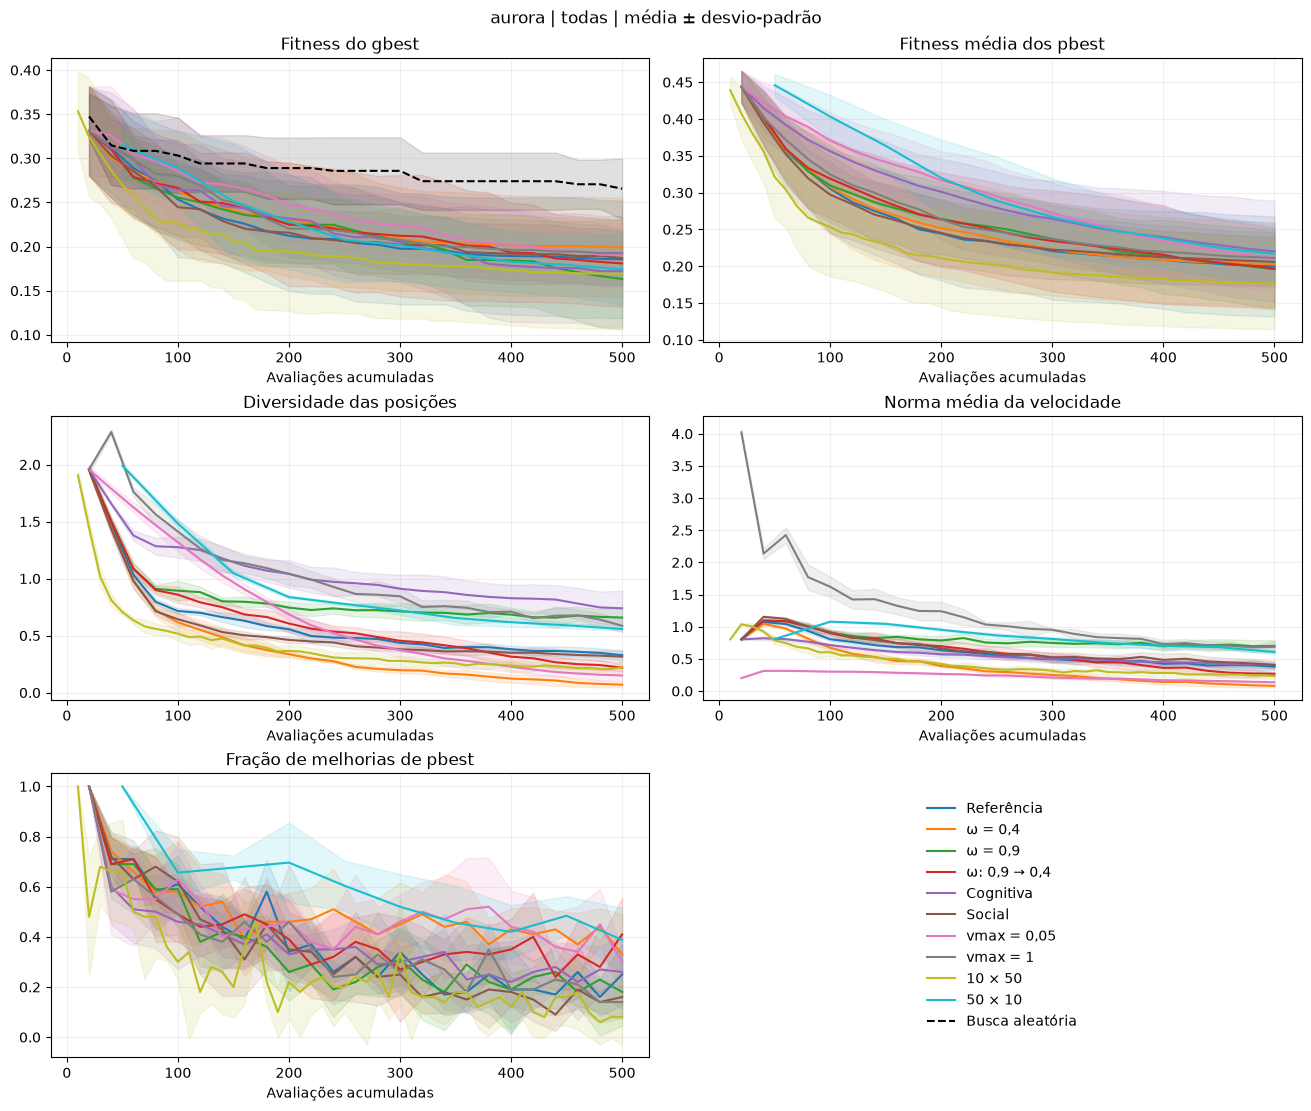

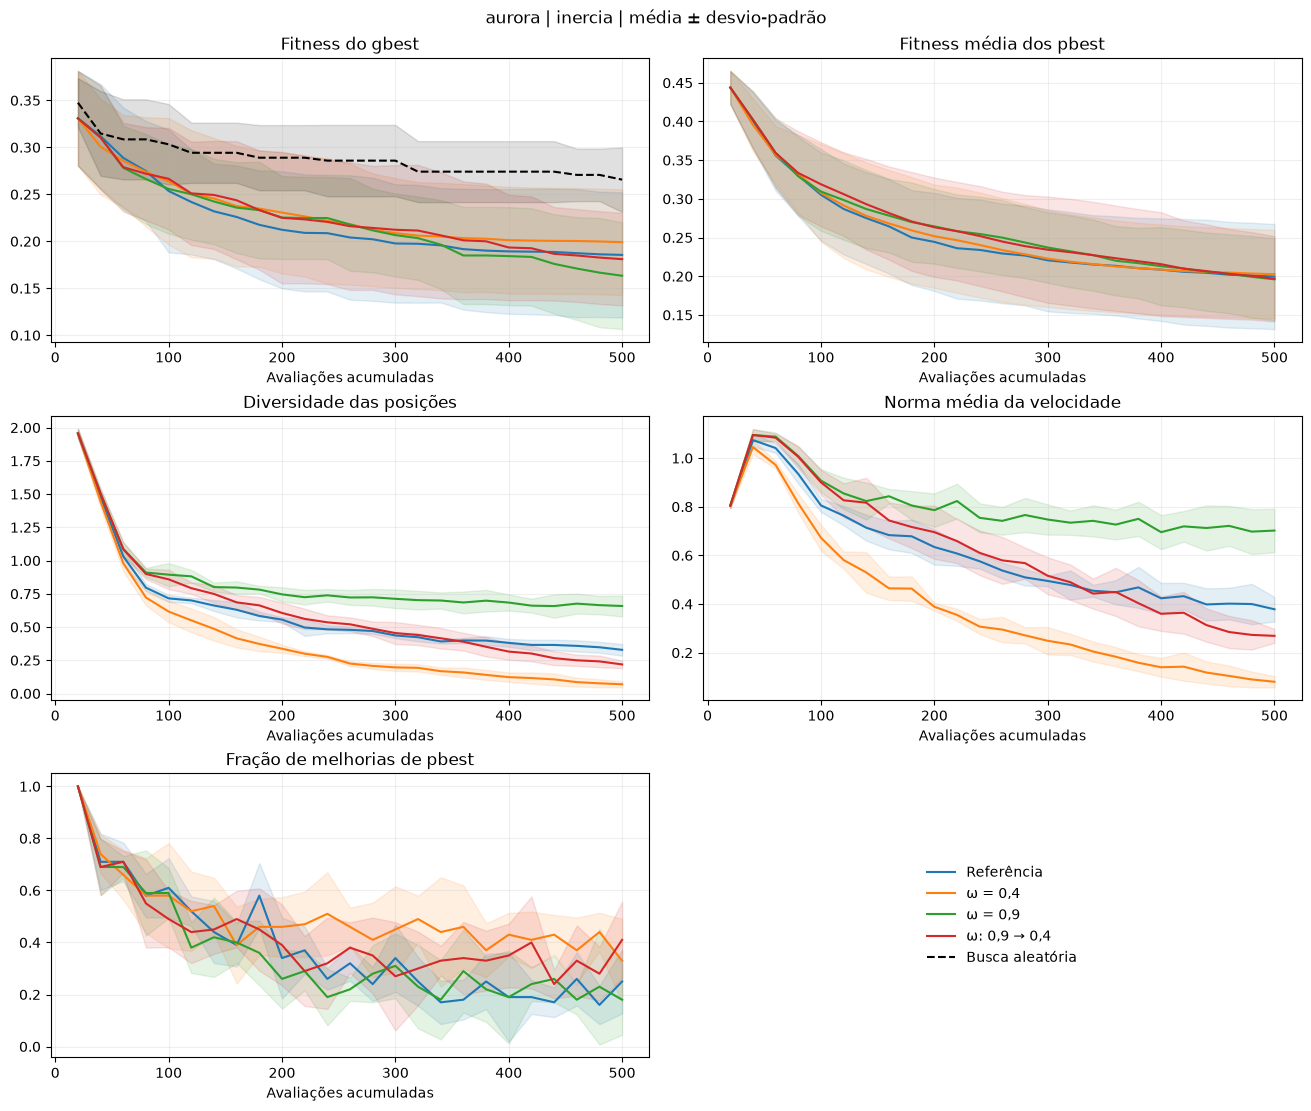

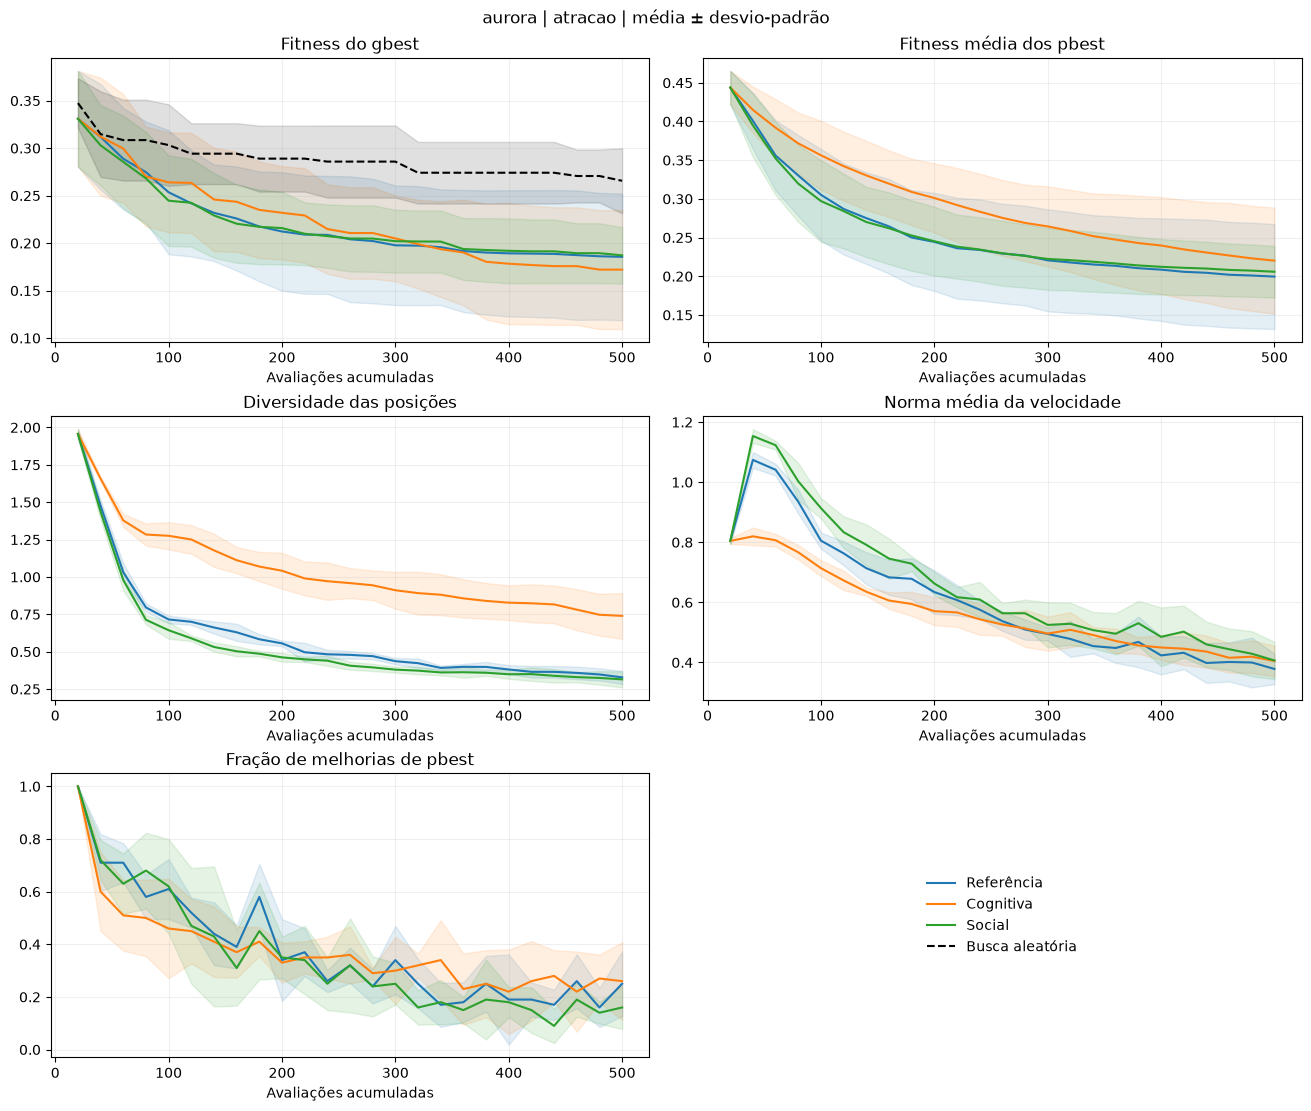

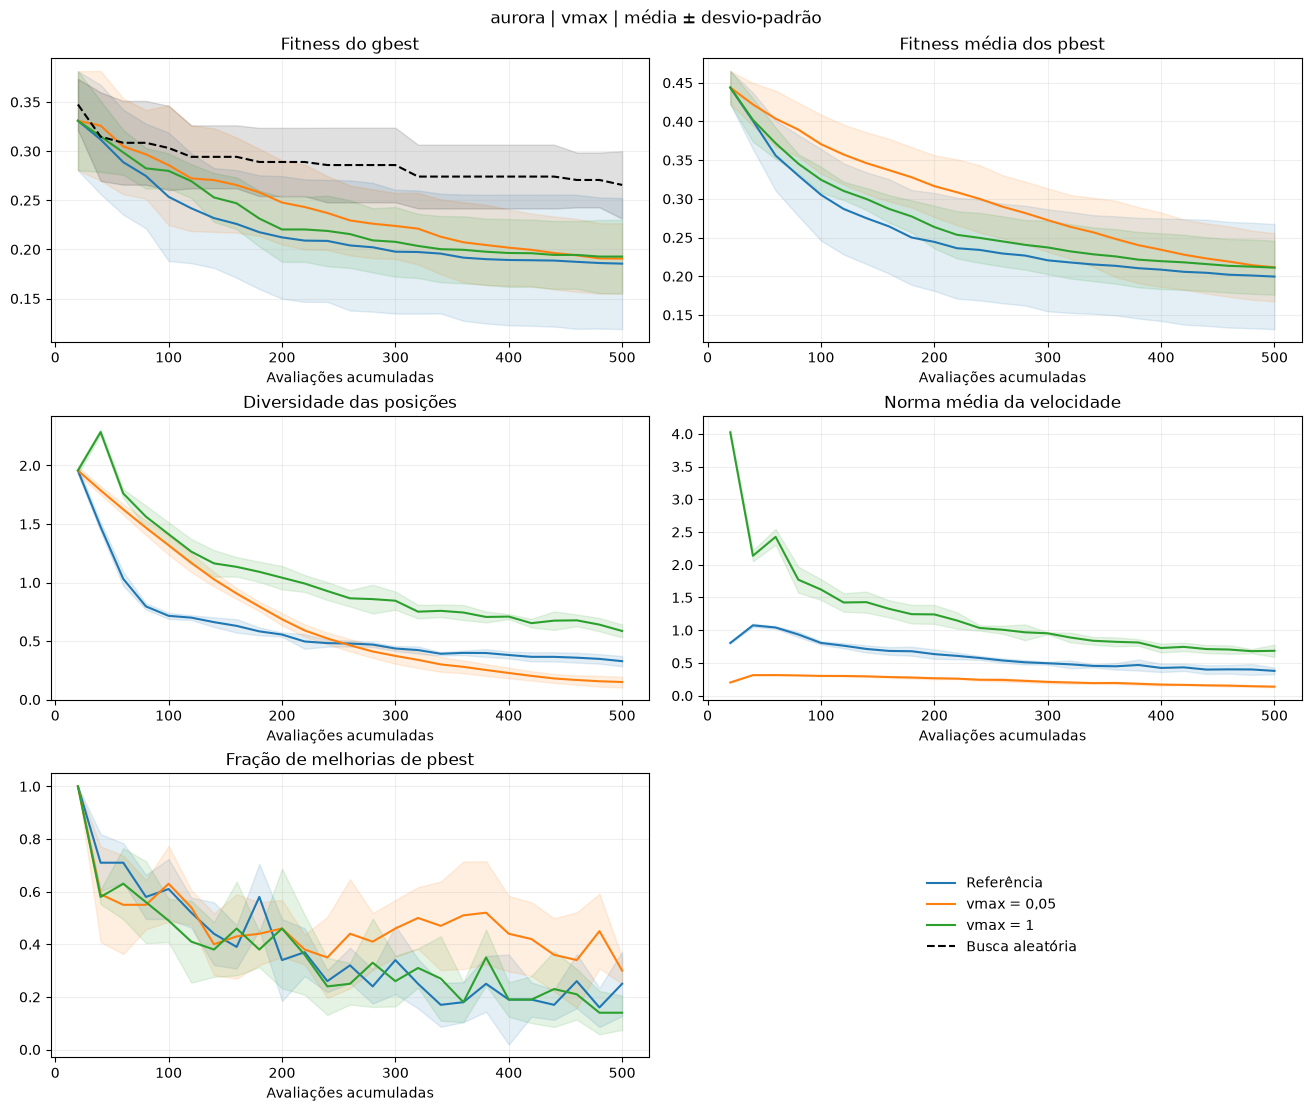

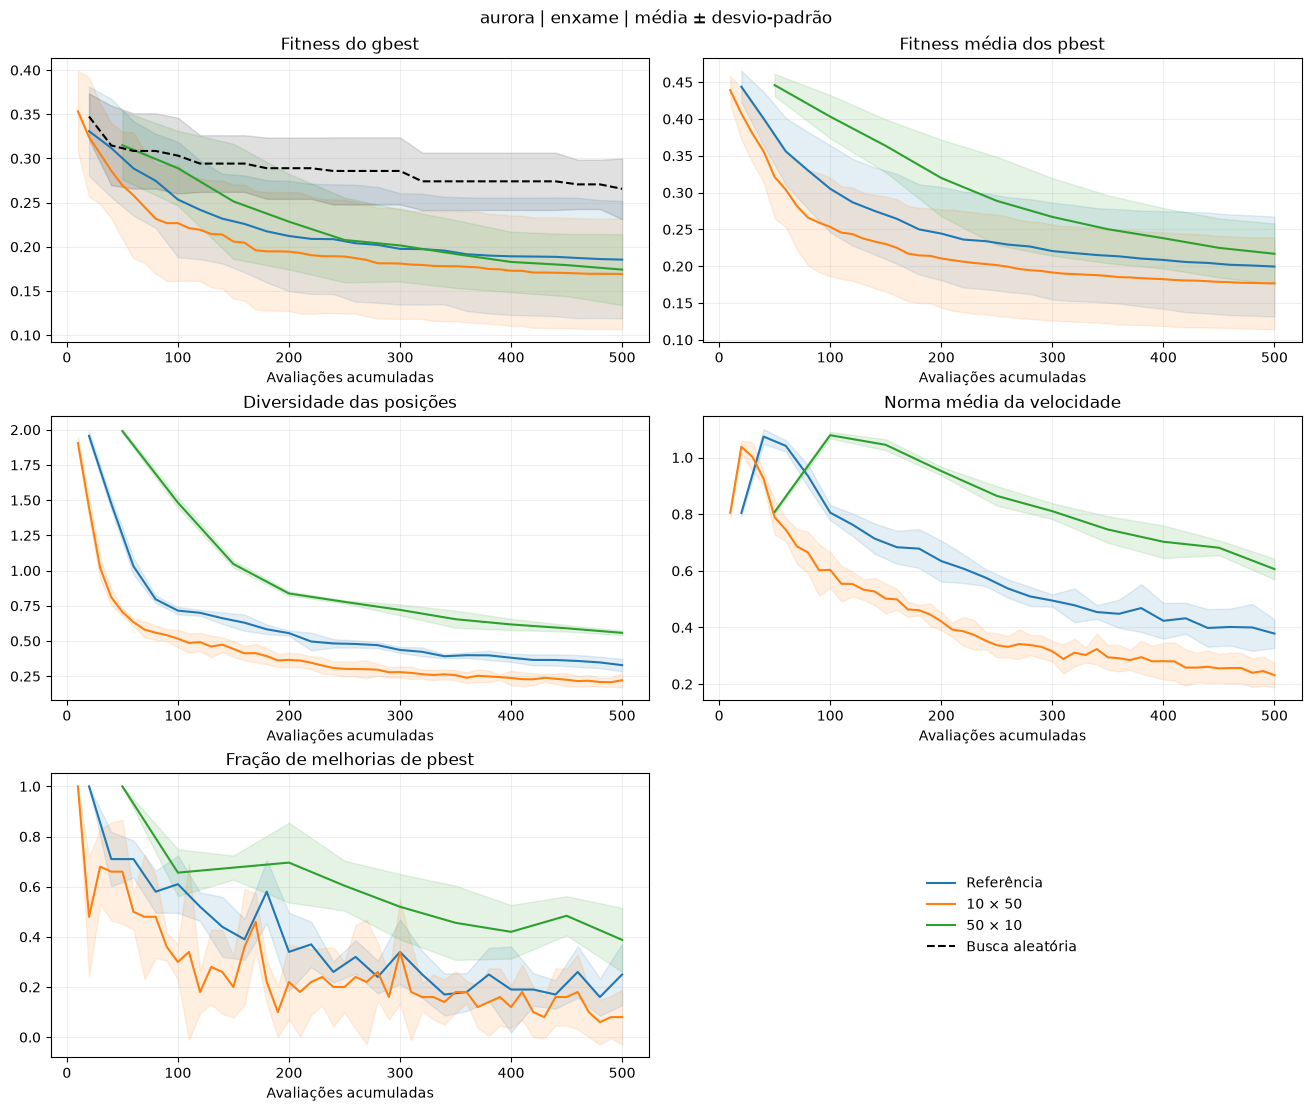

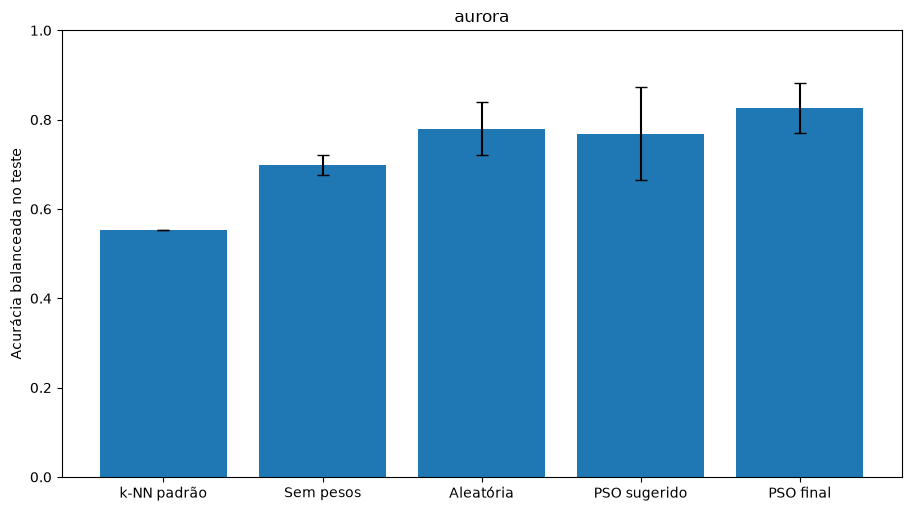

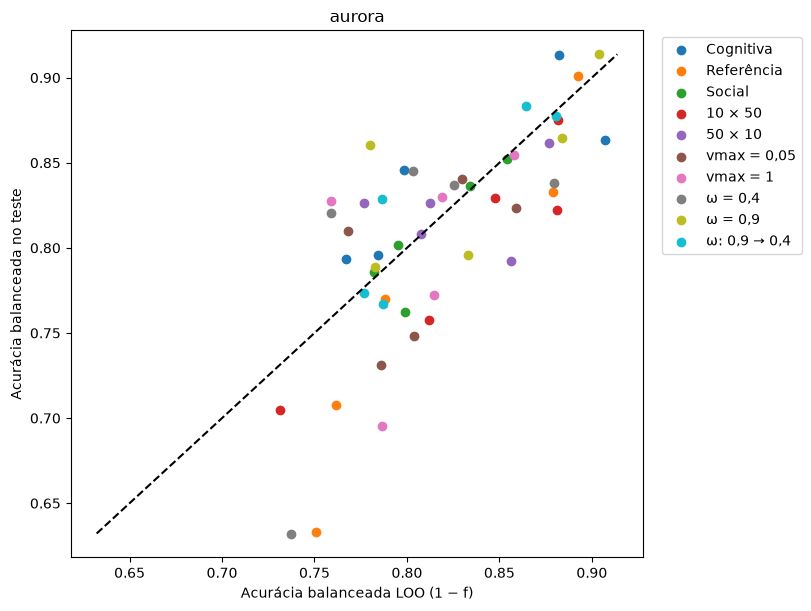

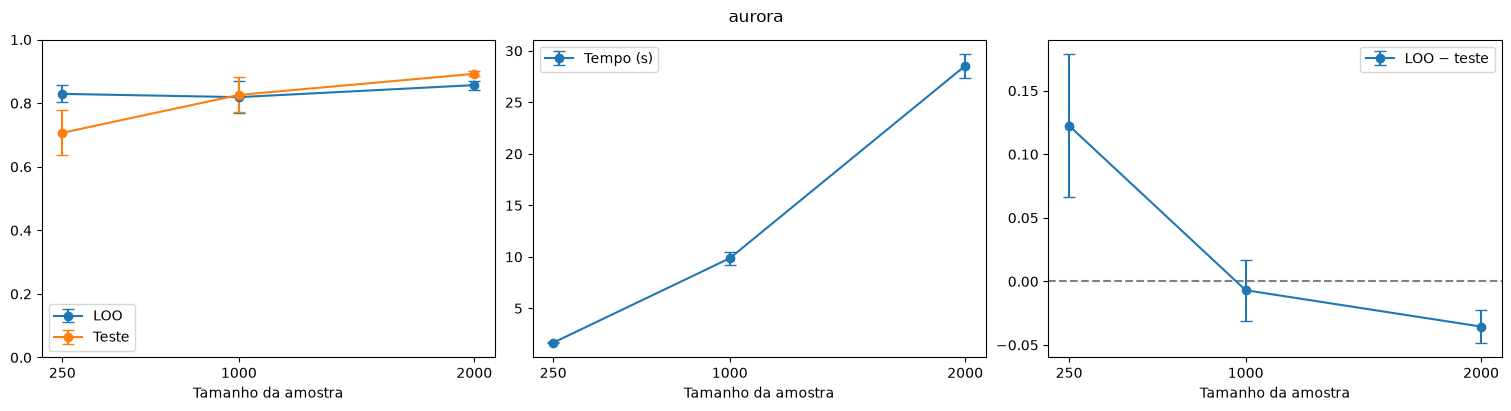

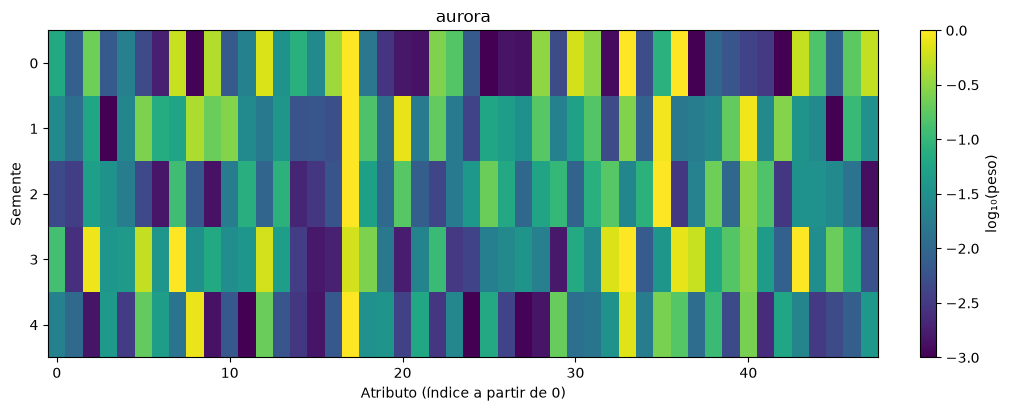

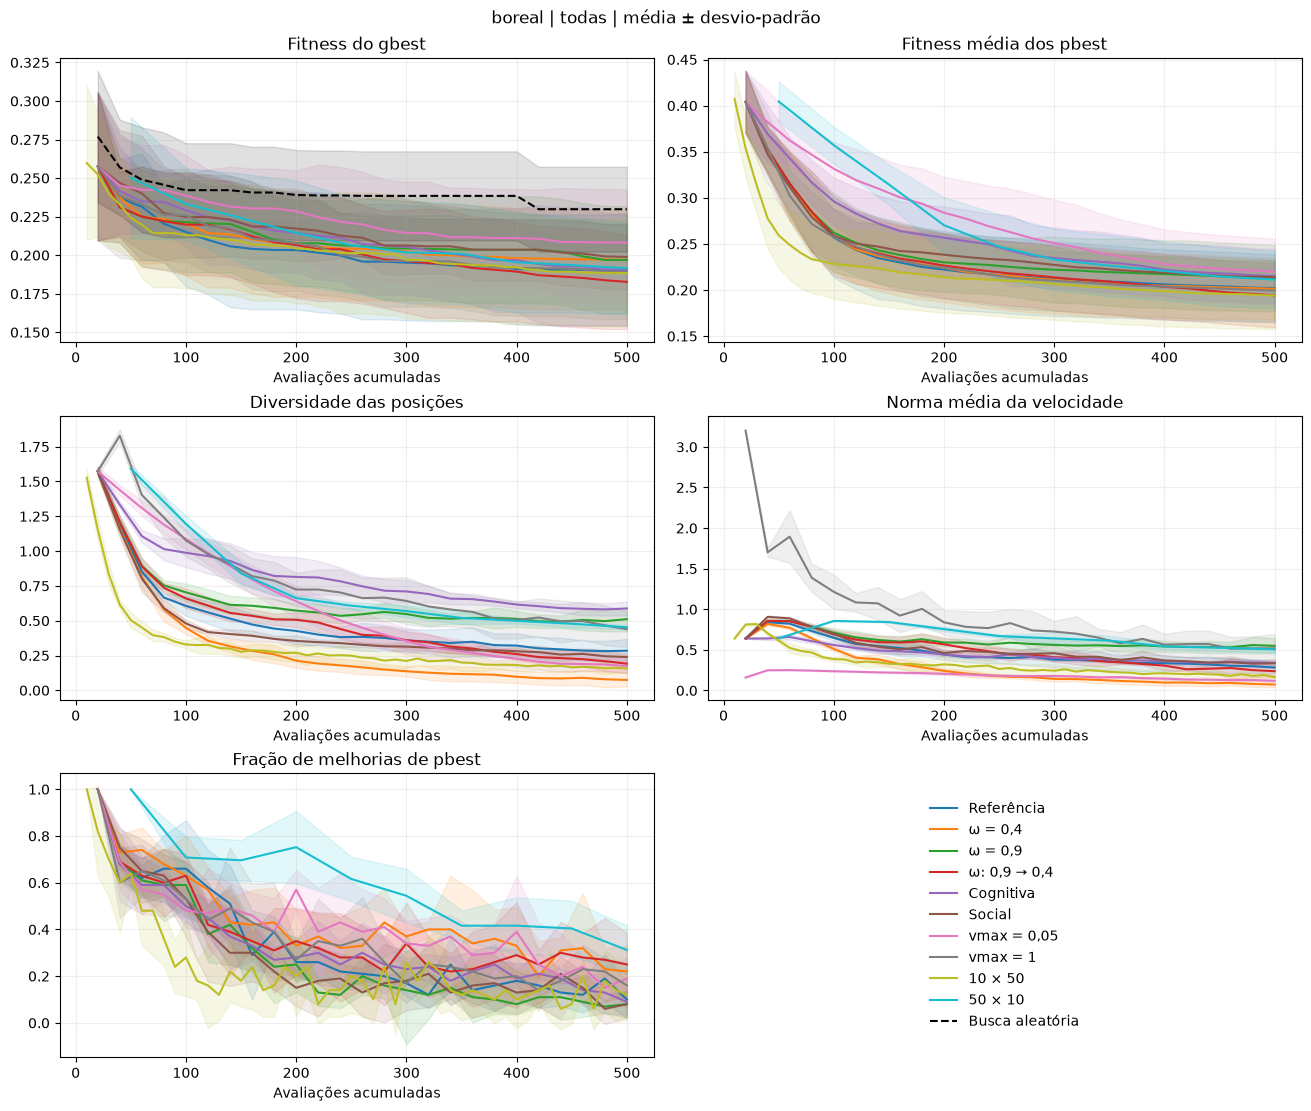

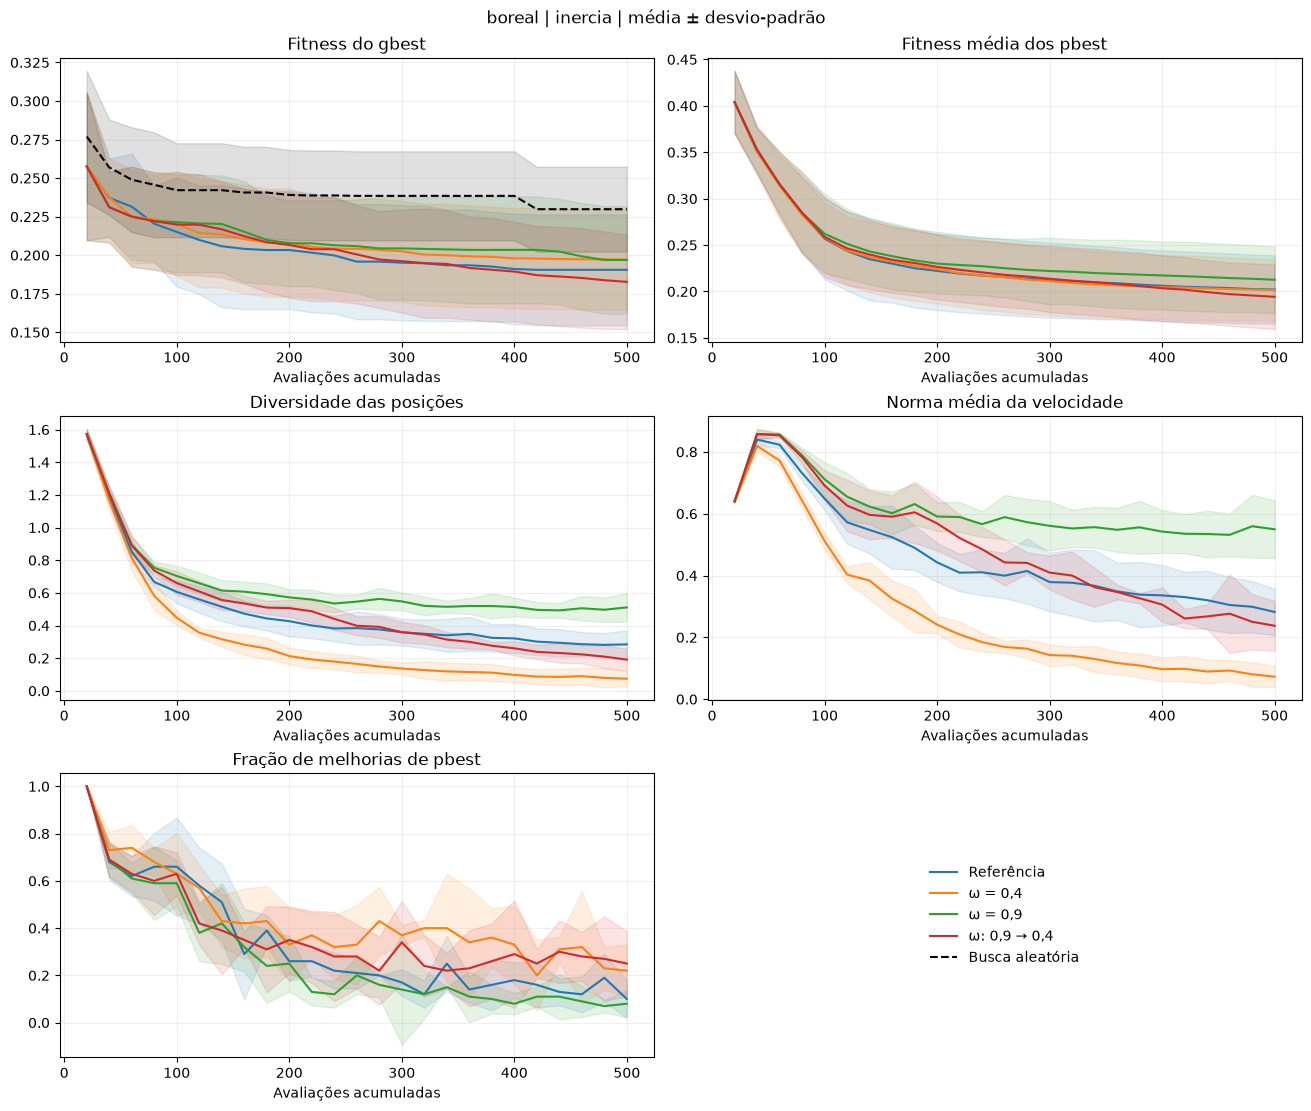

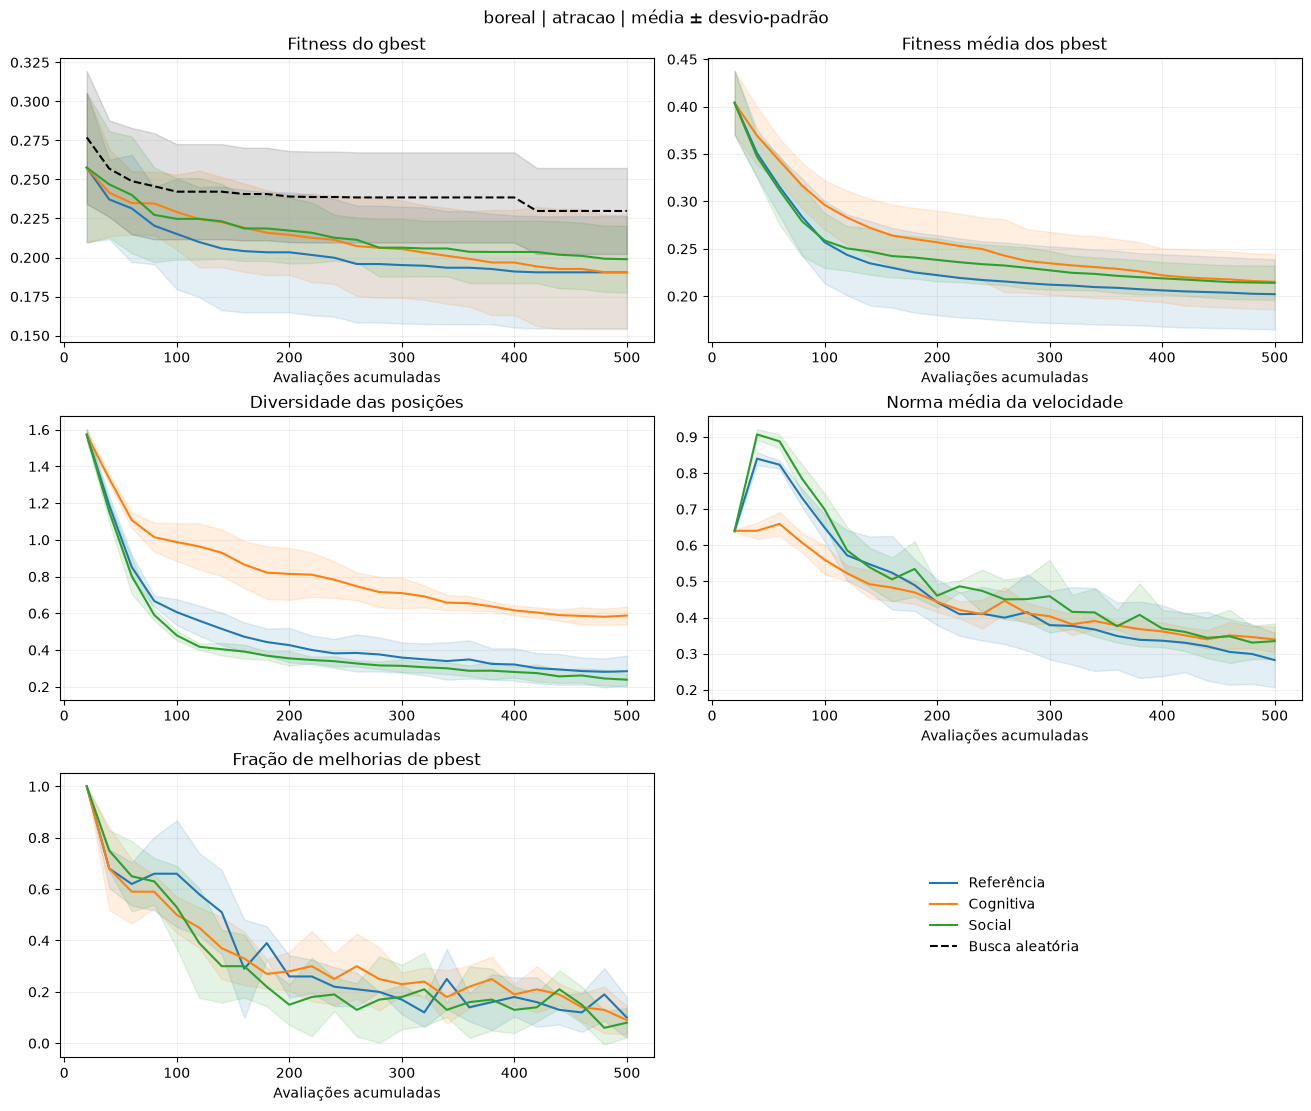

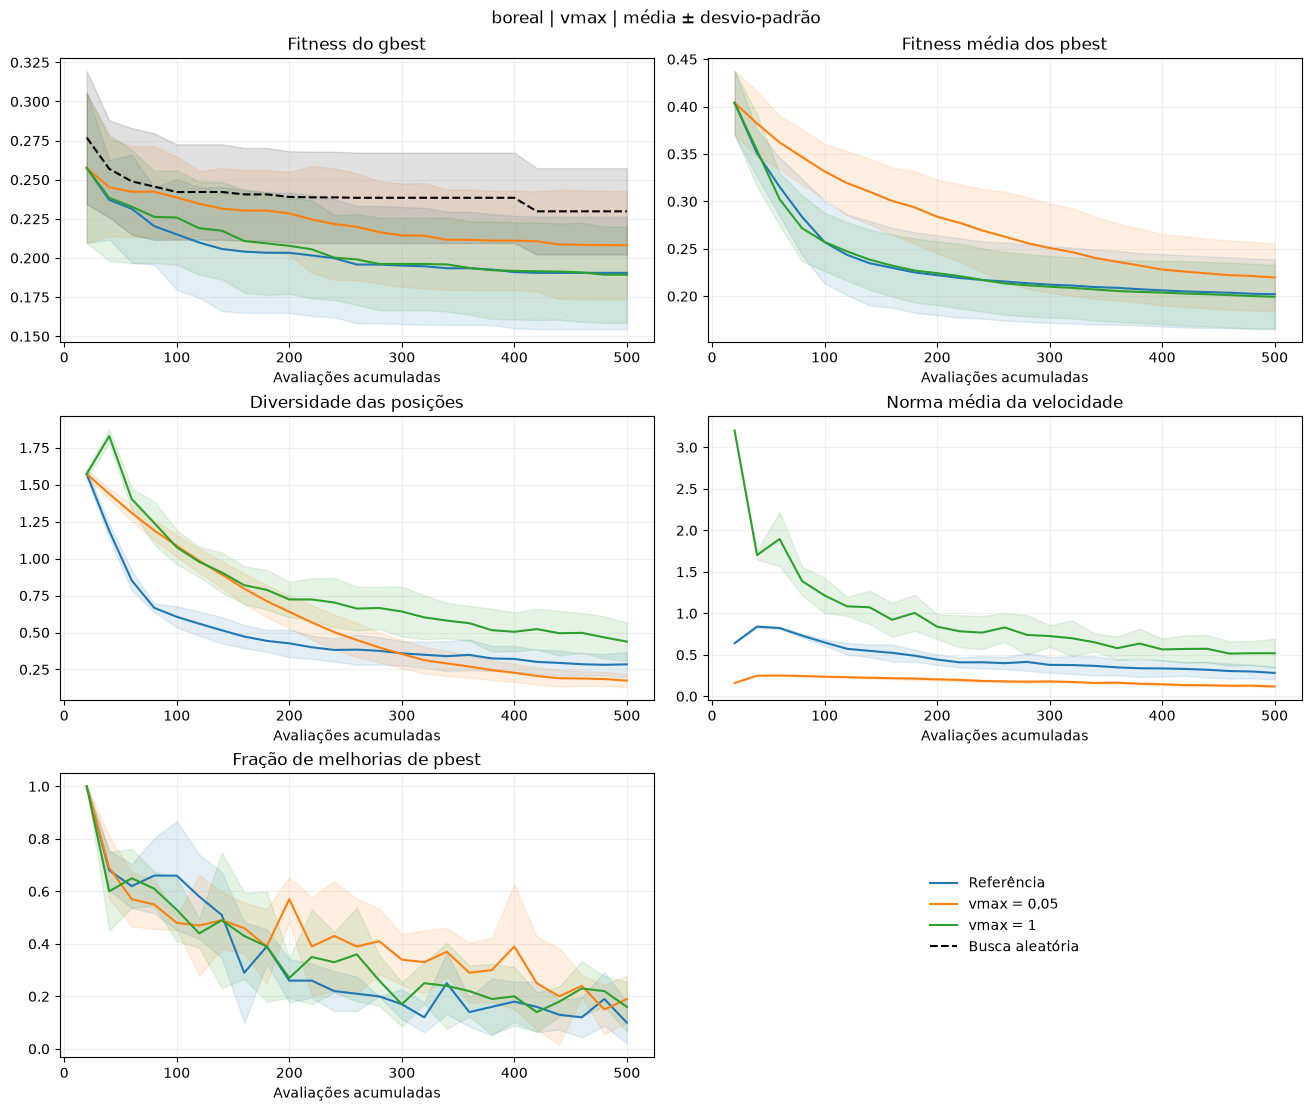

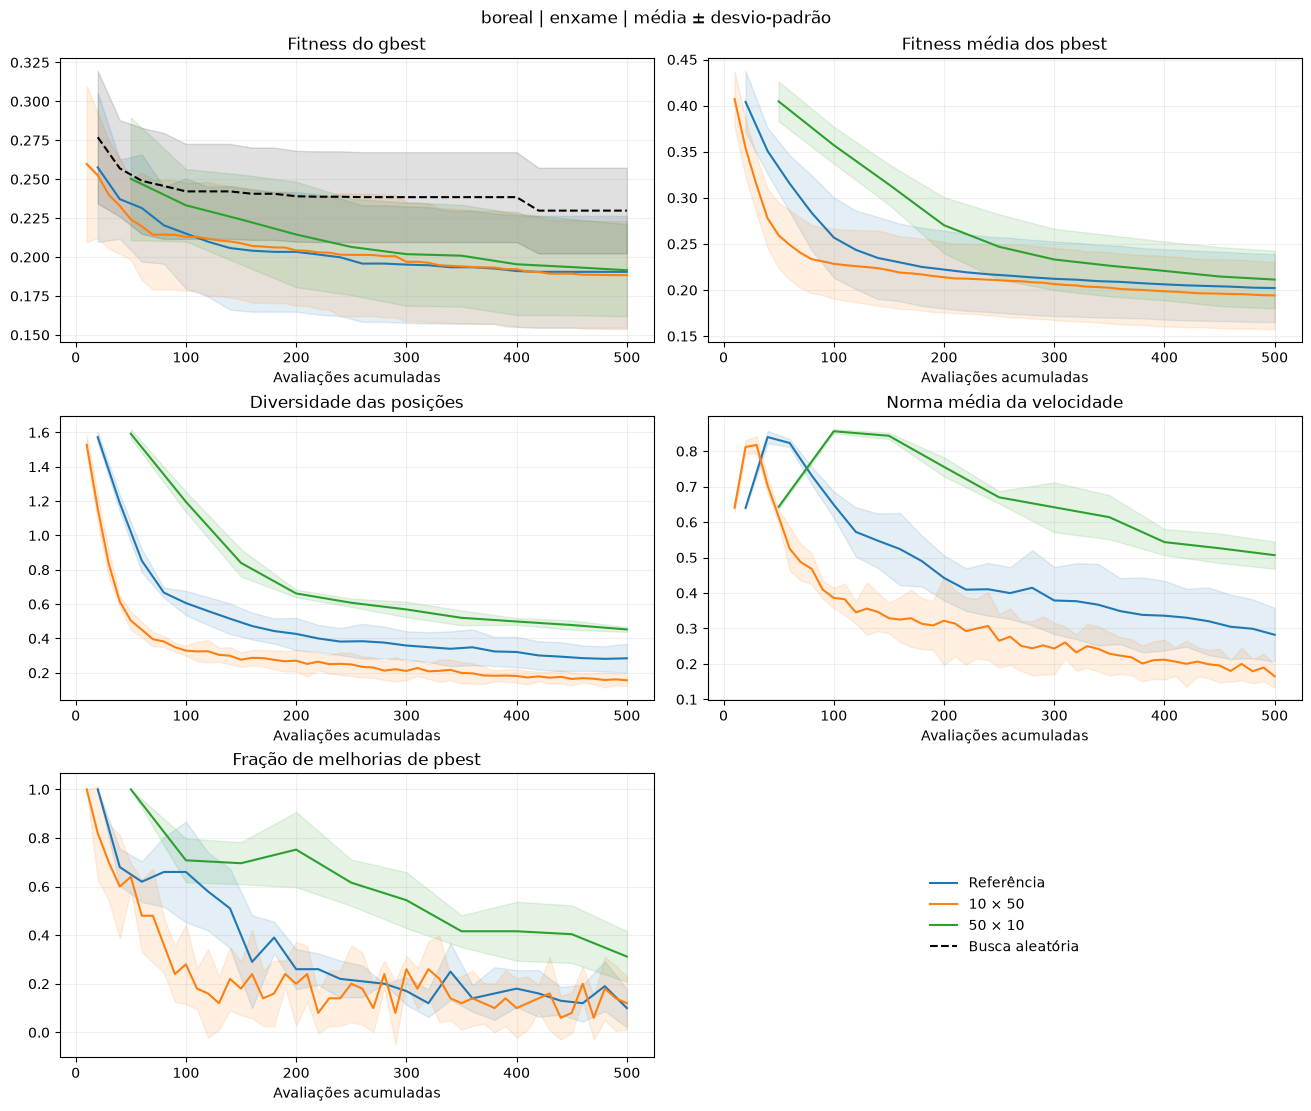

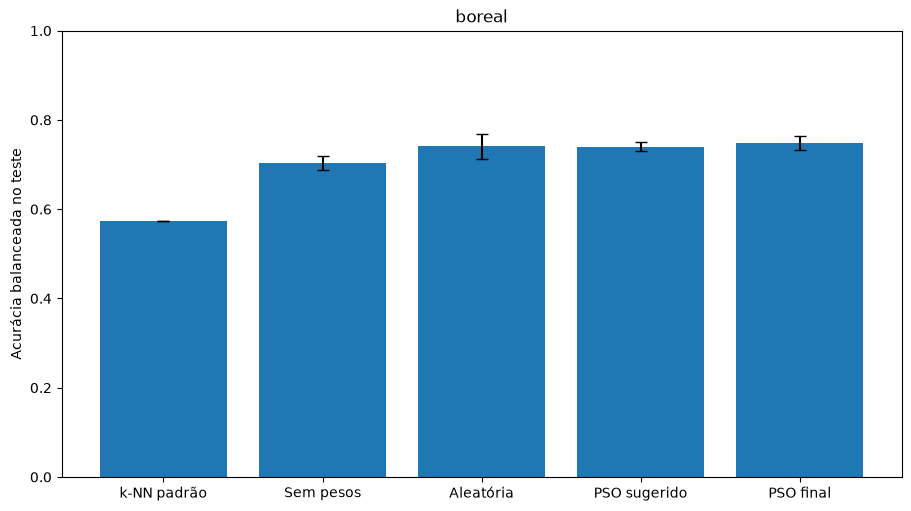

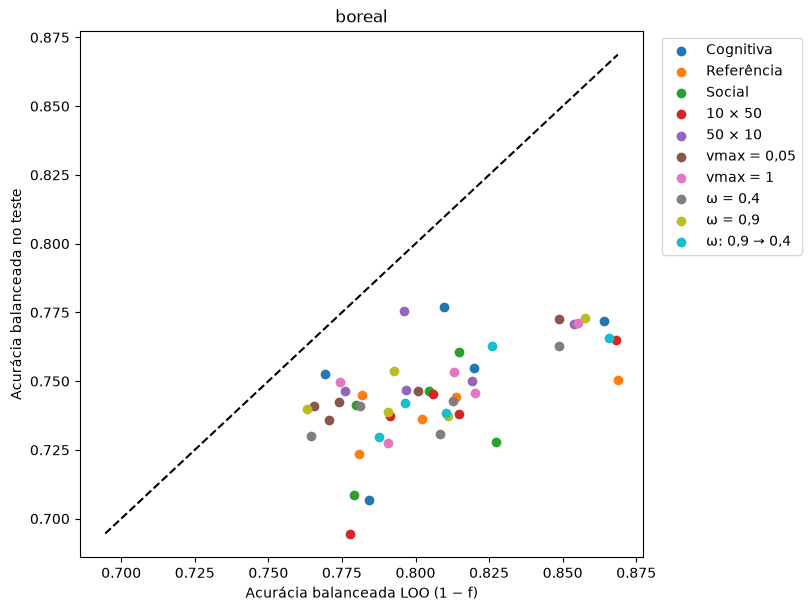

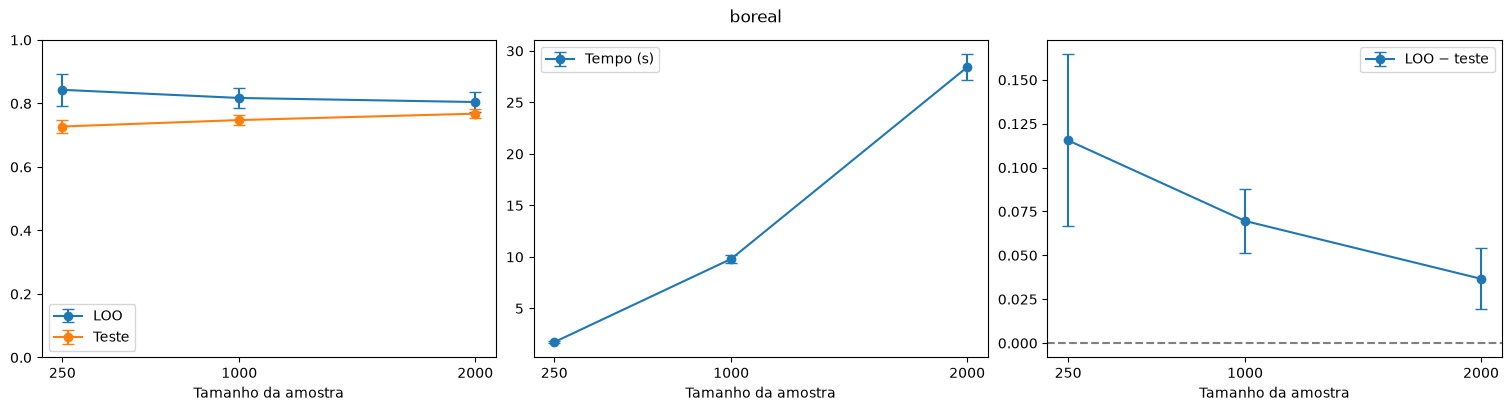

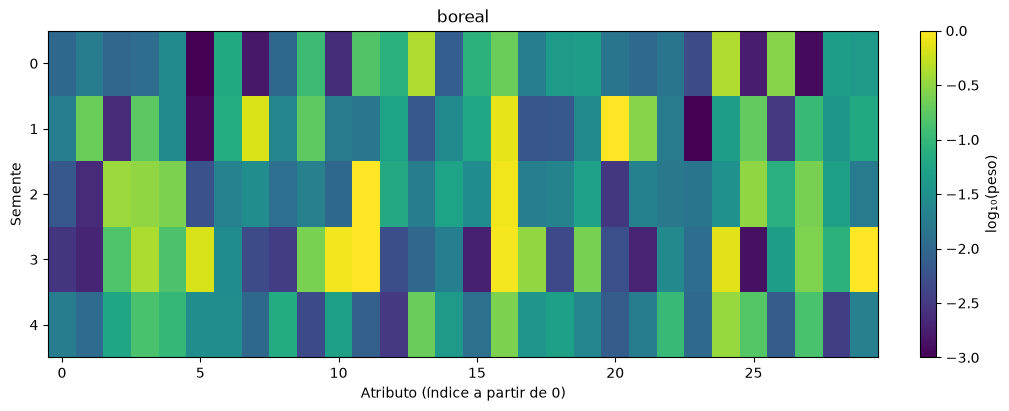

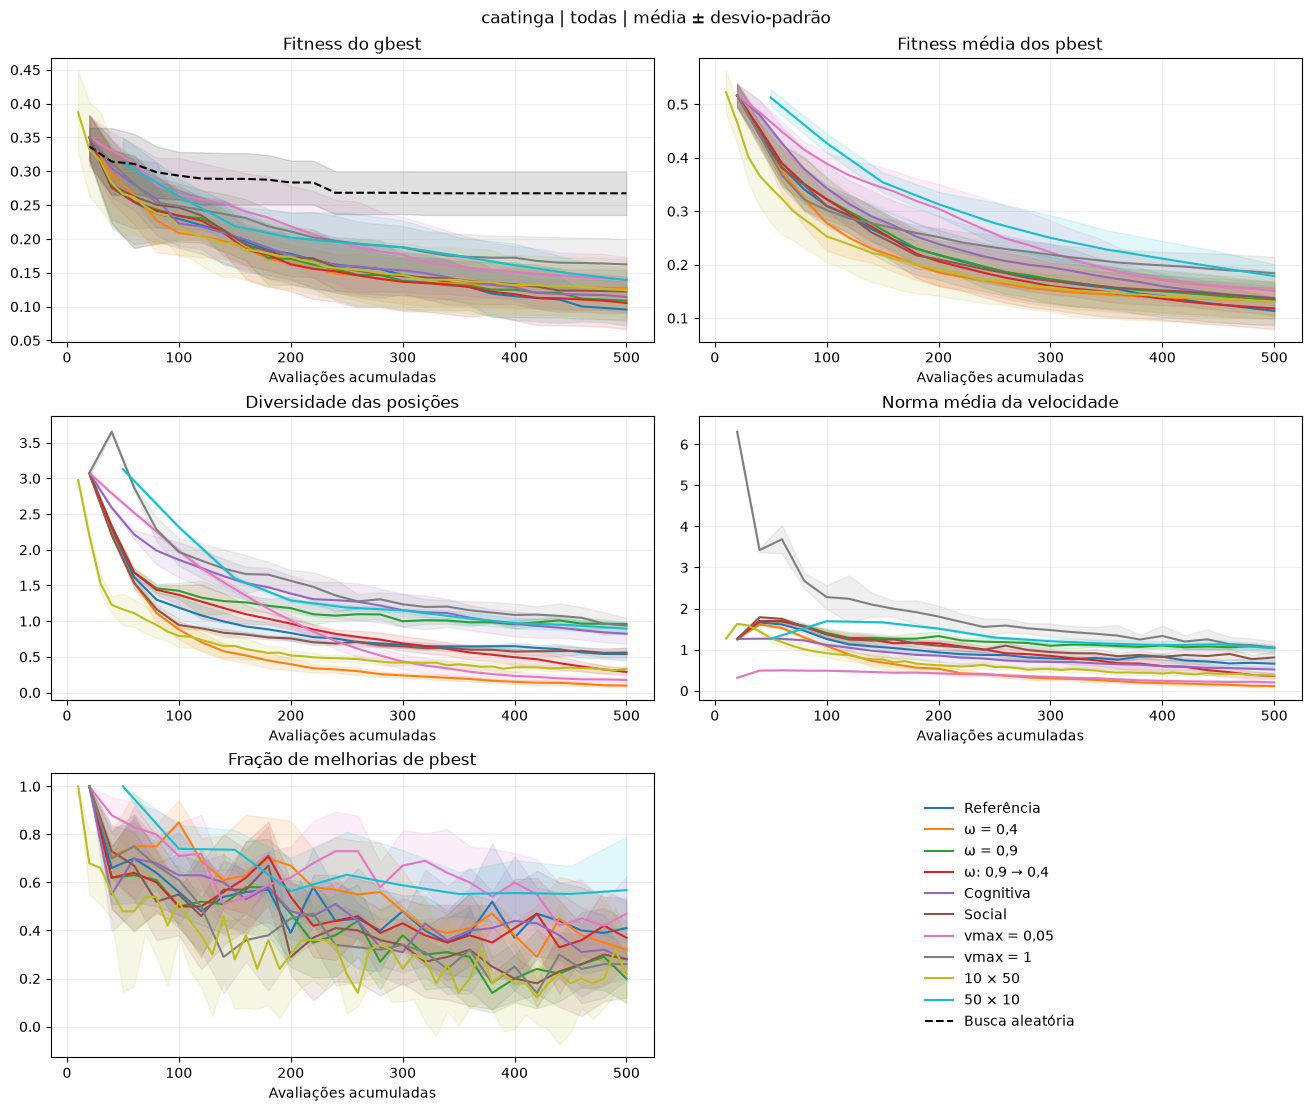

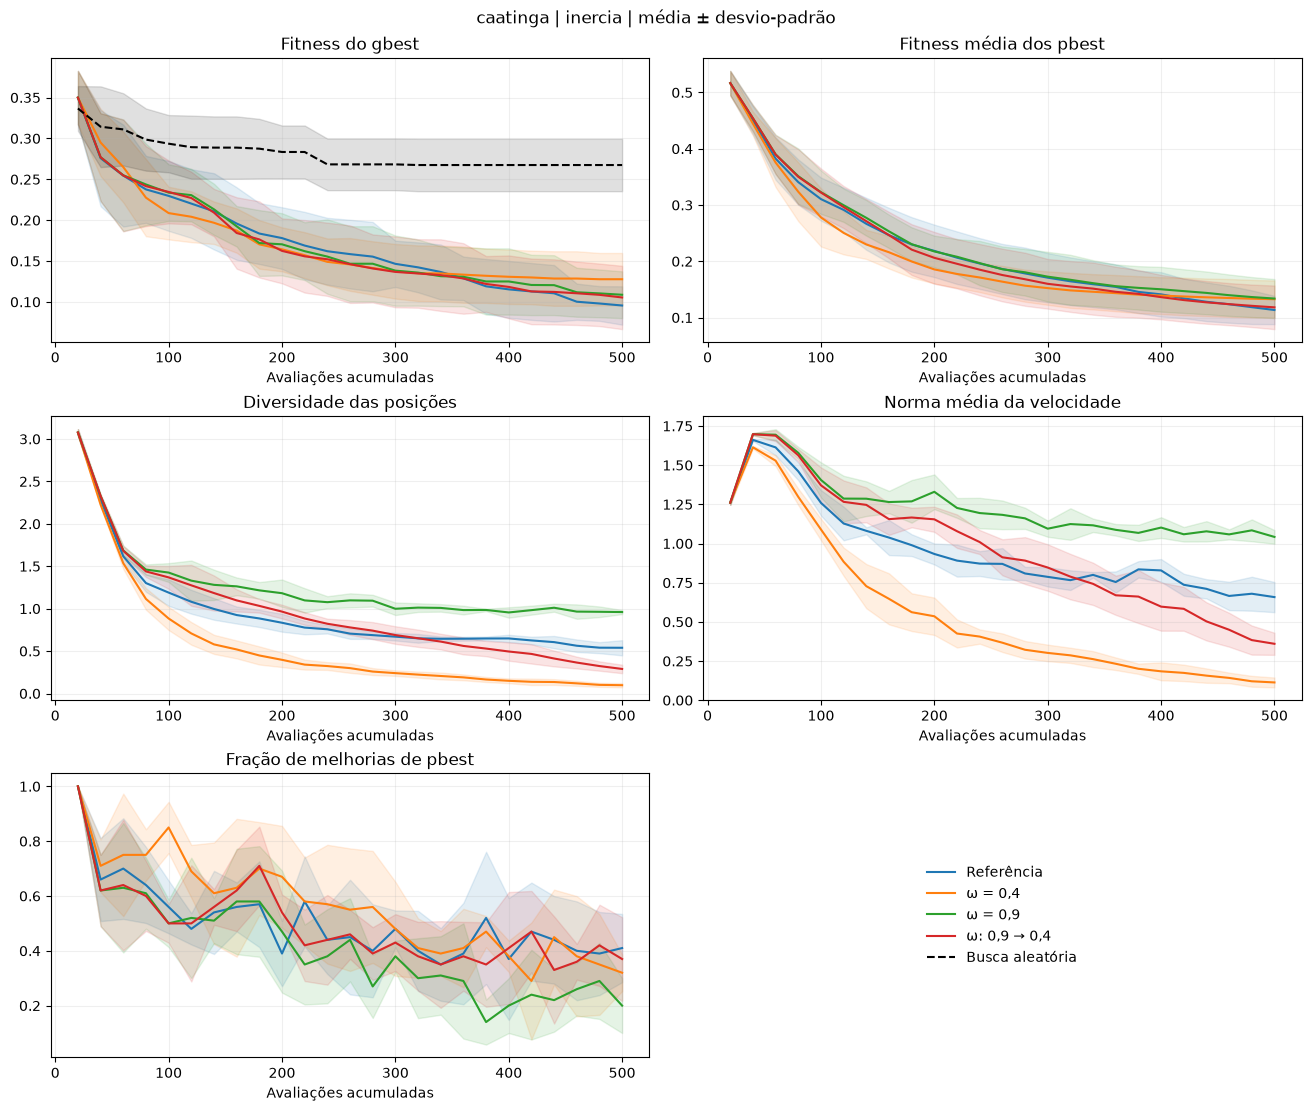

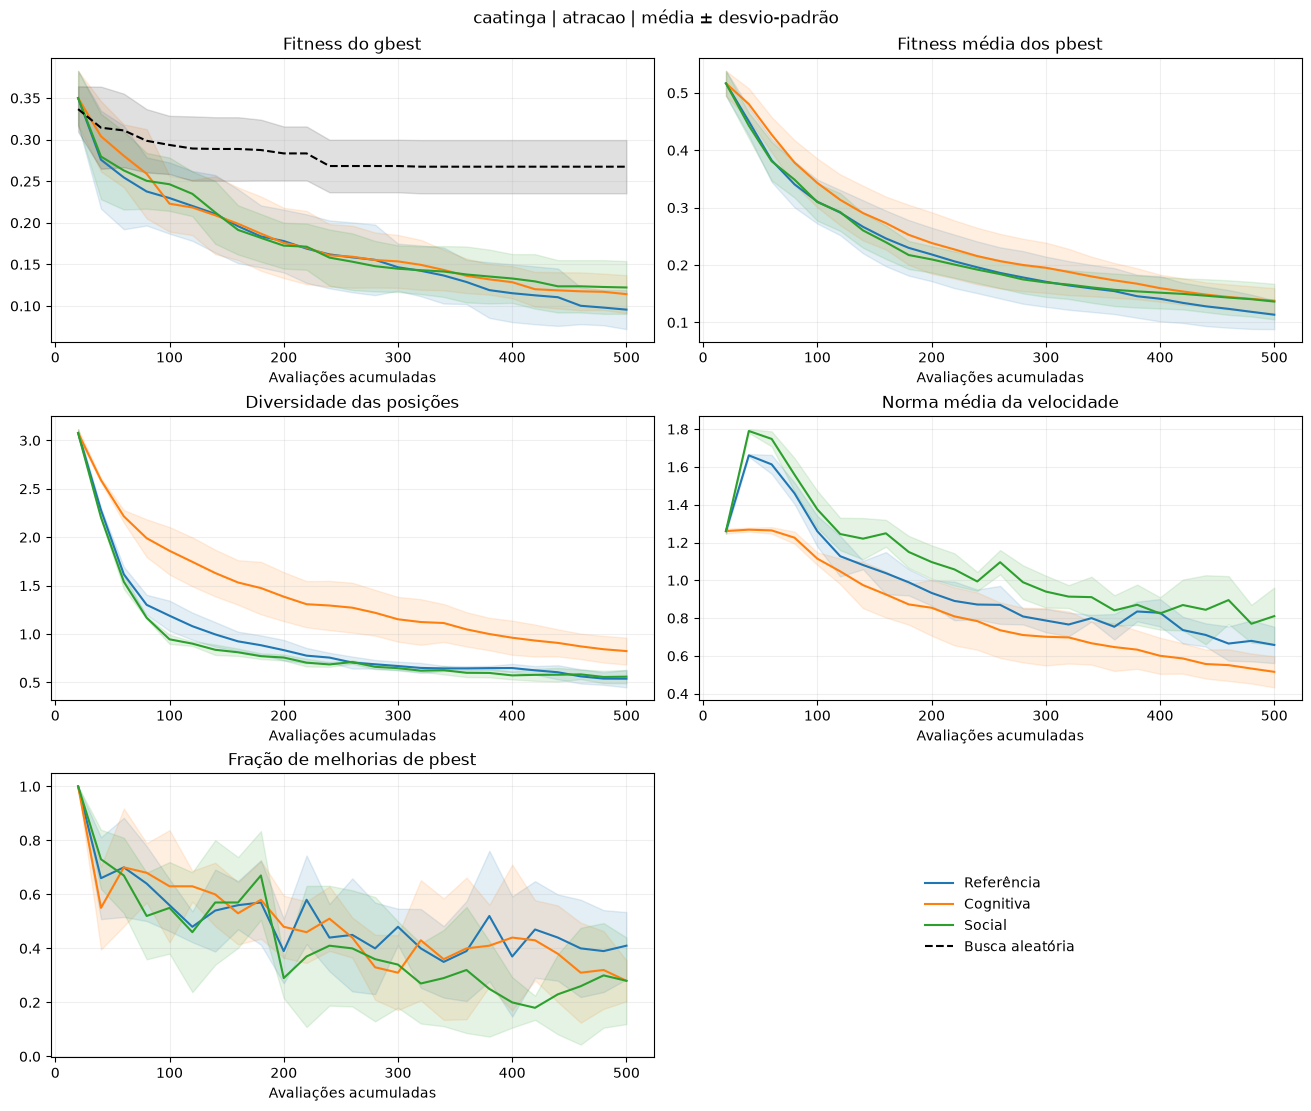

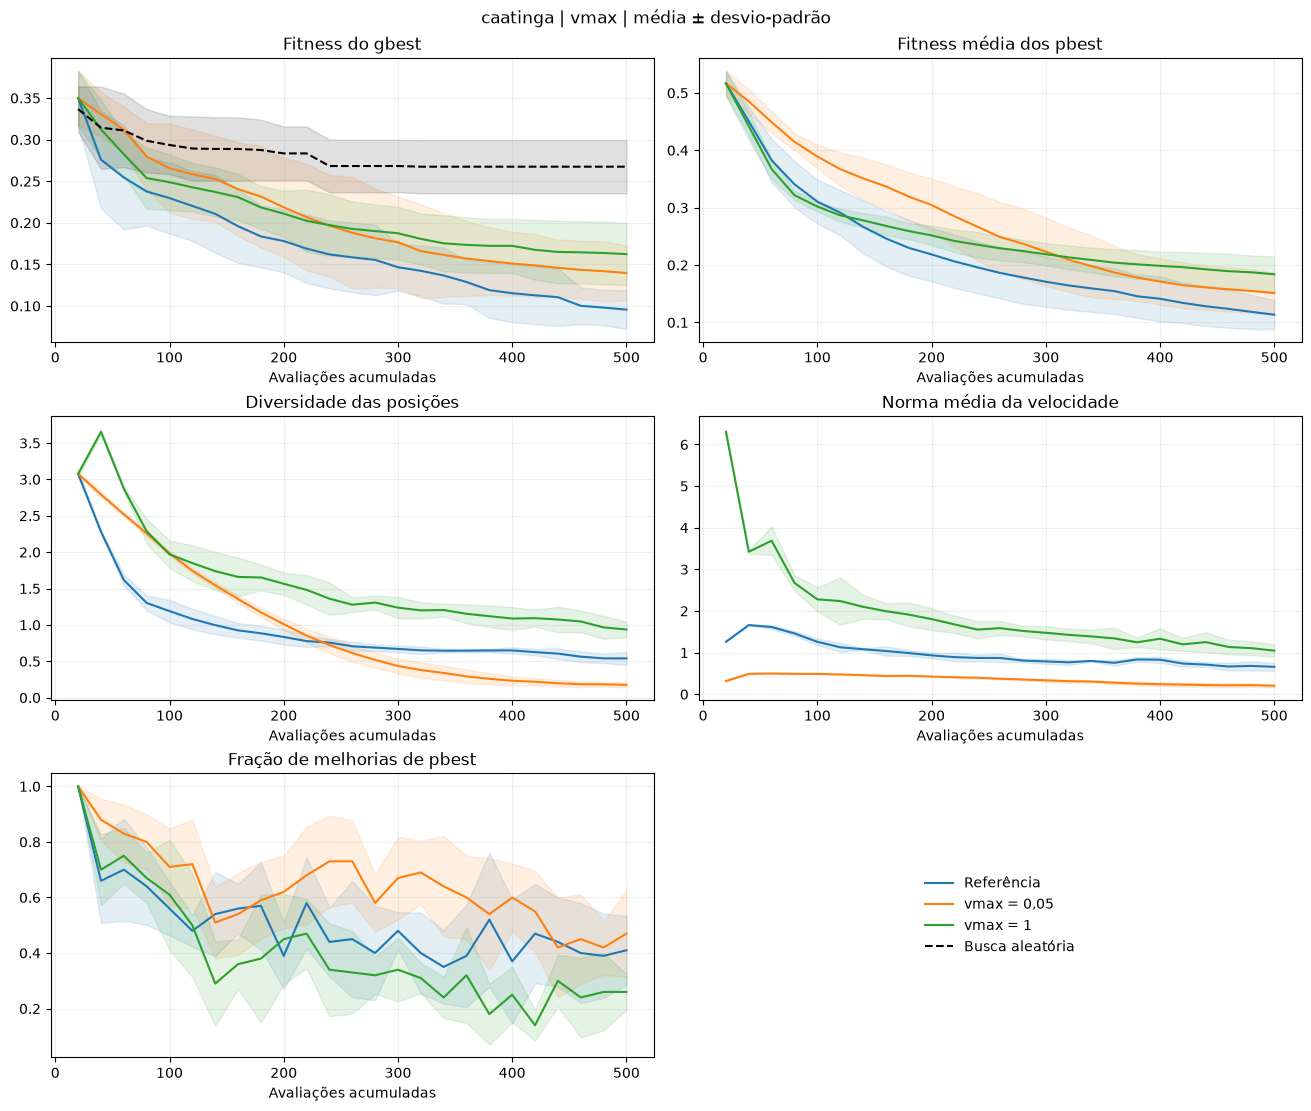

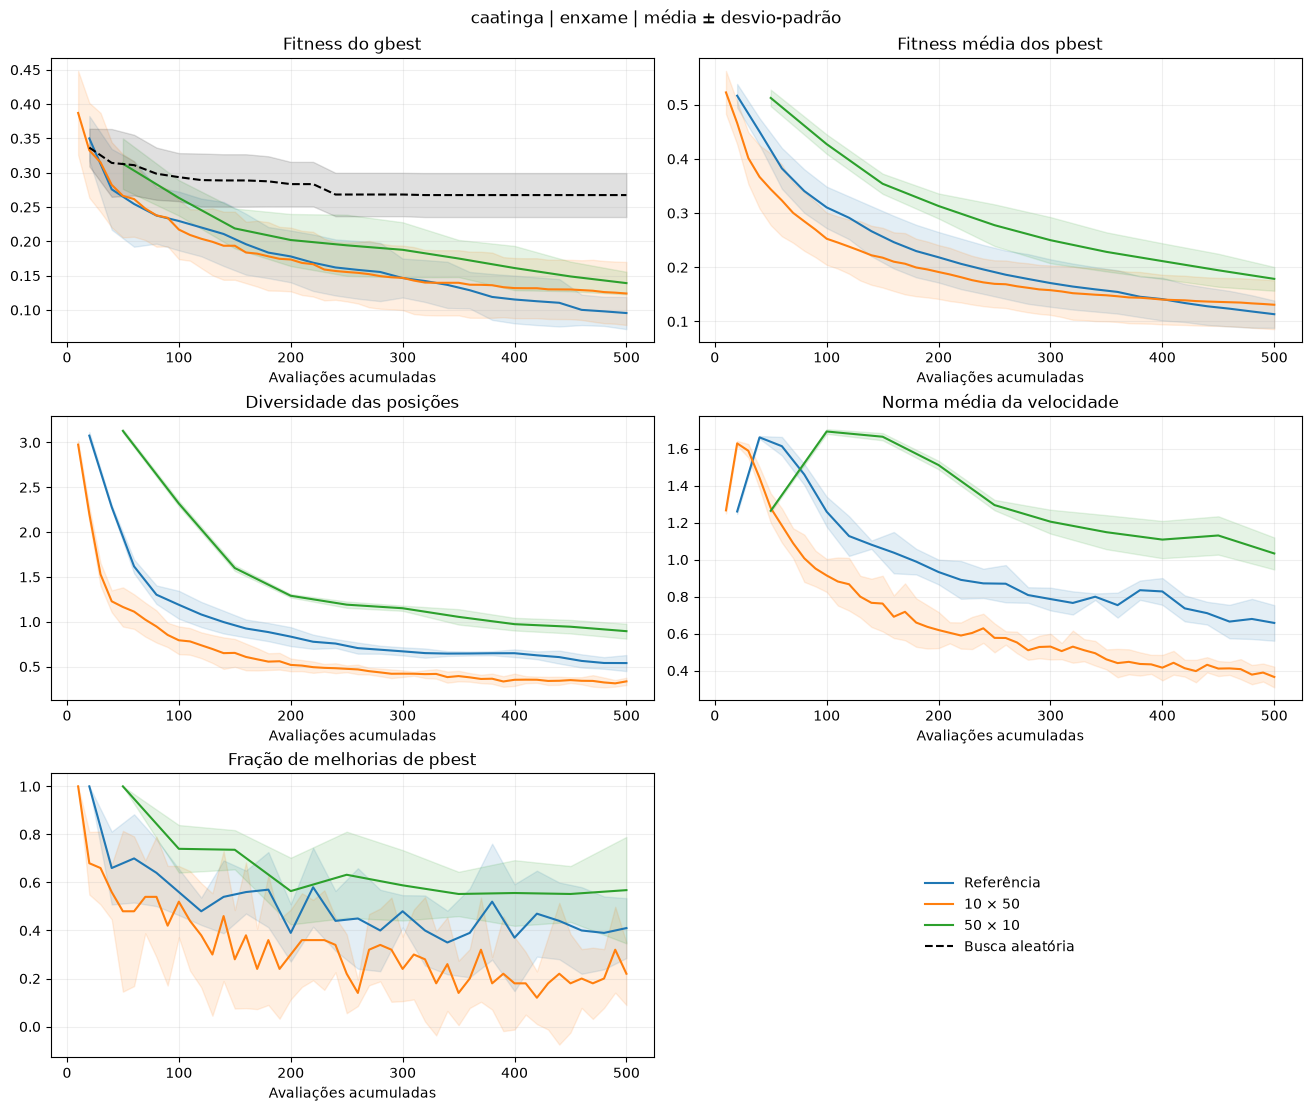

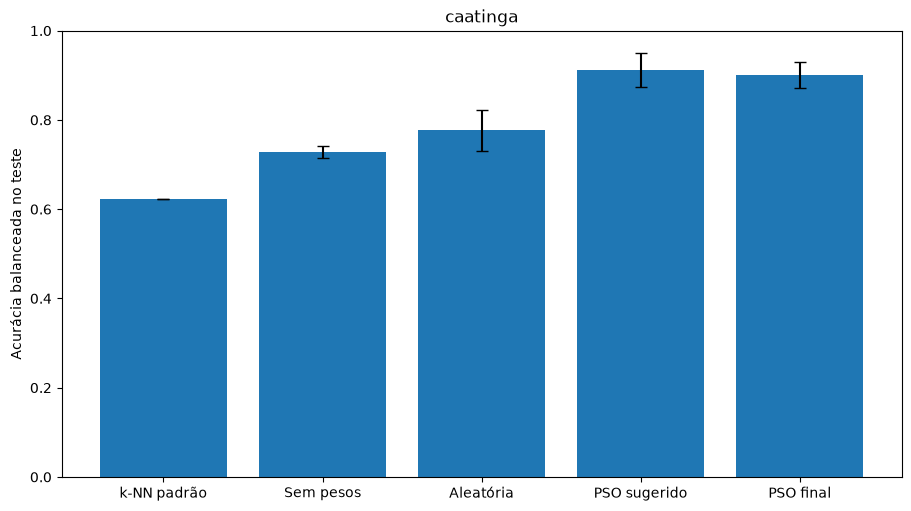

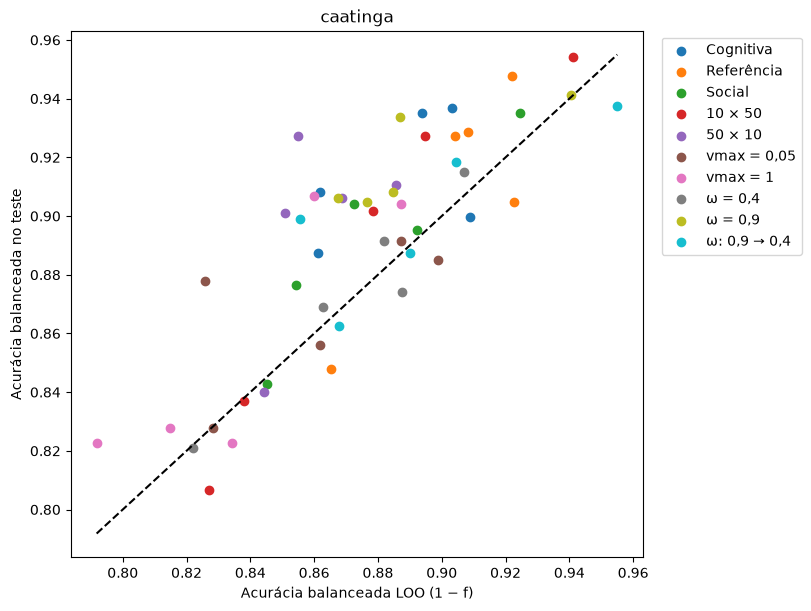

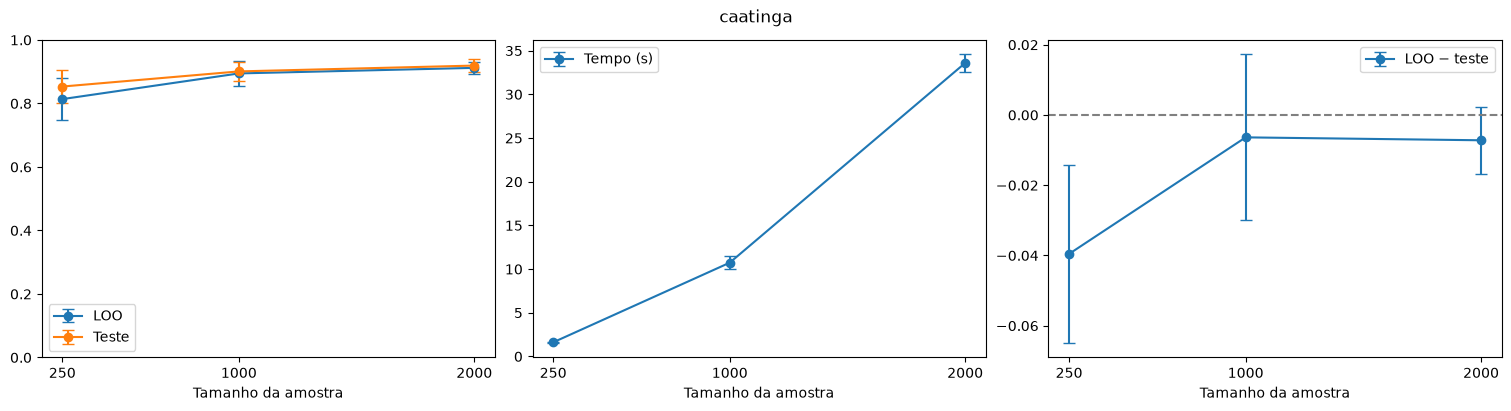

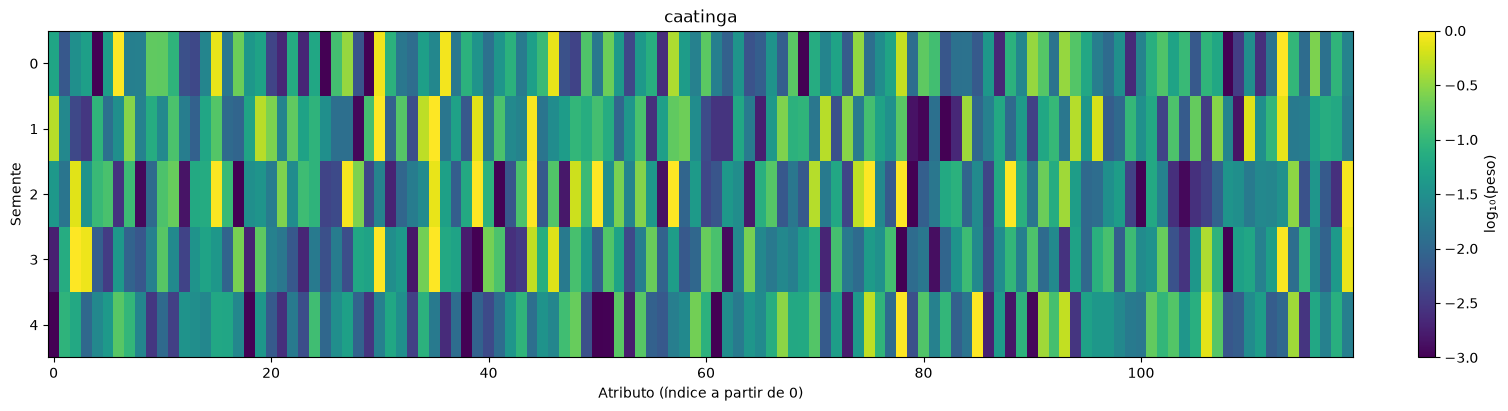

In [11]:
generate_figures(OUTPUT_DIR, SEEDS)
